# Four bare dies on one bench: ETROC2 **v2.01** and **v2.03** charge injection, FNAL, July 2024

**Chips** `ET2p03_BARE1`, `ET2p03_BARE4`, `ET2p03_BARE9` (three ETROC2 **version 2.03** bare dies)
and `ET2p01_BARE10` (one **version 2.01** bare die). No LGAD is bonded to any of them.
**Campaign** the FNAL bench, seven days between 2024-07-15 and 2024-07-30, one die per day.
**Pixels** 6: (row, col) ∈ {(0,0), (0,14), (3,0), (3,14), (12,0), (12,14)} — the same six as the
August-2024 X-ray campaign of notebook 03.
**Charges** 6, 7, 9, 16, 23 and 28 fC — the same six as the two January-2024 campaigns of
notebooks 01 and 02 (QSel 5, 6, 8, 15, 22 and 27; the injected charge is QSel + 1 fC, ETROC2
Reference Manual rev 0.60 §3.1.4, applied by the loaders since 2026-10-18).

"Gain" in this notebook always means the **preamp gain**: the charge-to-threshold response of
the front end, in threshold-DAC LSB per fC. No sensor is involved anywhere here.

This is the fourth measurement notebook of the folder, and it exists for three reasons the
census (notebook 00, row 5) already named:

1. **It is the only place where a v2.01 die and v2.03 dies were scanned on the same bench,
   days apart, on the same pixels and charges.** Notebook 04 compares the two revisions across
   two campaigns, two sites and two temperatures; here everything but the die is held fixed.
2. **`BARE9`, the X-ray die of notebook 03, was scanned here on 29 and 30 July — four days
   before its first day at CERN.** That is a pre-irradiation reference in an independent setup.
3. **`BARE4` is the die whose internal voltage reference notebook 00 measured in the climate
   chamber** (section 7.6 there). Its three bench days are the only charge injection that die
   ever took.

It imports the same `qinj_common.py` and therefore the same turn-off estimator, weighted preamp gain
fit, shared-σ S-curve fit and quantisation floor as notebooks 01–03. One thing this campaign
turned up applies retroactively to all three of them, and it has its own section (5): the
pixel (0,14) has a **compressive charge response on every one of six dies of both revisions** —
its turn-off saturates around 80–100 DAC above baseline while the other pixels reach 200–300 —
so it is not a representative pixel, and the pooled gains of notebooks 01–03 are pulled low by
its inclusion. Its cause is not resolved here.

## What this campaign did not record

No dose (none was given), no rail setting, no temperature, no elapsed time — the directory names
carry only chip, pixel, charge and threshold — and **no register read-back exists anywhere in
the tree**, so the analog-rail setting and every front-end register (RfSel, IBSel, QSel …) are
unknown for all seven days. Every absolute DAC number below is therefore *this die, on this day,
at whatever the bench was set to*; comparisons within a day and slopes are what survive that.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
import qinj_common as Q
from qinj_style import apply_style

apply_style(0.55)
pd.set_option("display.width", 200, "display.max_columns", 80)

LEDGER = []
RESULTS = {}

print("DAC LSB (assumed)    %.6f mV" % Q.LSB_MV)
print("TDC reference clock  %.3f ns" % Q.CLK_NS)
print("electrons per fC     %.3f" % Q.E_PER_FC)
print("operating point      threshold = BL + %d DAC" % Q.OP_OFFSET)
print("charges injected     %s fC" % Q.JUL_CHARGES)
print("pixels scanned       %s" % Q.JUL_PIXELS)
print("preamp gain-fit range       %d-%d fC (notebooks 01 and 02)" % (Q.JUL_QLO, Q.JUL_QHI))

DAC LSB (assumed)    0.390625 mV
TDC reference clock  3.125 ns
electrons per fC     6241.509
operating point      threshold = BL + 20 DAC
charges injected     [6, 7, 9, 16, 23, 28] fC
pixels scanned       [(0, 0), (0, 14), (3, 0), (3, 14), (12, 0), (12, 14)]
preamp gain-fit range       9-28 fC (notebooks 01 and 02)


## 1. Provenance

Everything read here is under `data/bench_jul2024/`. It is the reduction of one raw tree,
`fermilab-etroc3:/run/media/daq/X9/et2p03_qinj_data/2024-07-*_Array_Test_Results/` (48 659
files, 38.8 GB), copied to LPC and to LPC EOS
(`/eos/uscms/store/user/lpcmtdstudies/fnal_Jul2024_bench/raw/`) with file count, byte sum and a
146-file md5 sample verified at each hop. `DECODE_README.md` is the reduction's own
documentation, shipped verbatim; `reduce_bench.py` is the reduction script, which is
notebook 03's `reduce_tid.py` with a flat directory walk and every per-point function copied
unchanged. The decoder it calls is this repository's `DecodeBinary`, byte for byte.

| file | RAW / DERIVED | what it is |
|---|---|---|
| `jul_et2p03_points.feather` | RAW + DERIVED | per-point TOA/TOT/CAL moments, all-hit and CAL-windowed, one row per decoded point directory, 22 756 × 42 |
| `jul_et2p03_turnoff.csv` | RAW | the 252 discriminator binary searches, whole search as `search_trace` |
| `jul_et2p03_noiseonly.csv` | RAW | the 42 `quietCB` noise scans, one per day and pixel |
| `jul_et2p03_configs.csv` | RAW + DERIVED | one row per bench day |
| `jul_et2p03_blnw.csv` | RAW | the single autocalibration map of the campaign, `BARE4` on 07-17, 256 pixels |

Unlike notebook 03 there is no independent hand-decode cross-check for this set; the July
`DECODE_README.md` says so. The ledger in section 12 checks the tables against each other
and against the README's own counts instead.

In [2]:
prov = pd.DataFrame([Q.file_row(p) for p in sorted(Q.JUL_DIR.iterdir()) if p.is_file()])
prov["MB"] = (prov.bytes / 1e6).round(3)
print(prov[["file", "bytes", "MB", "md5"]].to_string(index=False))
print("\nthe repository's own decoder, TestBeam/condor_at_lxplus/core/decoding.py, md5 289ef6cb7b7e48589e02d817de5060ed")
print("staged ../bare_et2p03_tid_aug2024/code/decoding.py (the copy reduce_bench.py imports)   md5",
      Q.md5(Q.ET2P03_DIR / "code" / "decoding.py"))

                     file   bytes    MB                              md5
         DECODE_README.md   13540 0.014 e99d28d5e0320f9f310ed0377cc57434
      jul_et2p03_blnw.csv   14815 0.015 f05abfa54c46415238e04d710f607d2a
   jul_et2p03_configs.csv    1236 0.001 5b2813ef38571200a867d8ce69a7fb29
 jul_et2p03_noiseonly.csv   16761 0.017 06e12f498bcda57be19a971b9c7876b0
jul_et2p03_points.feather 3703770 3.704 369bc6a9a95d84c8e50d42266f098210
   jul_et2p03_turnoff.csv   88228 0.088 70bcb7b0f1c673d14276b04efe24064a
          reduce_bench.py   17828 0.018 87e47bc286c7d4b516eba72acbaa54d6

the repository's own decoder, TestBeam/condor_at_lxplus/core/decoding.py, md5 289ef6cb7b7e48589e02d817de5060ed
staged ../bare_et2p03_tid_aug2024/code/decoding.py (the copy reduce_bench.py imports)   md5 289ef6cb7b7e48589e02d817de5060ed


In [3]:
PTS = Q.load_jul_points()
TOF = Q.load_jul_turnoff()
NOI = Q.load_jul_noiseonly()
CFG = Q.load_jul_configs()
MAP = Q.load_jul_blnw()
ACQS = list(CFG.acq)            # the seven acquisitions, in date order
DIE_OF = dict(zip(CFG.acq, CFG.chip))
print("acquisitions:", ACQS)

acquisitions: ['v2.03_BARE1 07-15', 'v2.03_BARE4 07-16', 'v2.03_BARE4 07-17', 'v2.03_BARE4 07-18', 'v2.01_BARE10 07-22', 'v2.03_BARE9 07-29', 'v2.03_BARE9 07-30']


## 2. The campaign: seven days, four dies

One die per day; `BARE4` for three consecutive days and `BARE9` for two. The first five days
were written as `.nem` text, the last two as `.bin` — the same two formats notebook 03 reads
with the same two code paths. Two of the seven days are flawed, and the table says how:

* **07-18 (`BARE4`): the noise-only scans are unusable** — every one of the six reports its peak
  at DAC 1, i.e. the counter never rose — and pixel (3,0)'s binary search sat at the DAC ceiling
  (1019) for every charge up to 16 fC. The other five pixels' searches on that day are fine and
  reproduce 07-16 and 07-17 to a DAC; they are kept as a third repeat of `BARE4`, but nothing
  that needs a baseline is taken from 07-18.
* **07-17 (`BARE4`): a short day** — 1 101 threshold points against 3 200–4 100 on the others, so its
  money-plot coverage is thin (one to three pixels per threshold offset); its turn-offs and
  noise scans are complete.

`BARE9` on 07-29 and 07-30 sits at two very different absolute DAC ranges (344–610 against
585–846). Section 7 shows that the whole difference is a baseline offset at unchanged slope.

In [4]:
day_rows = []
for acq in ACQS:
    p = PTS[PTS.acq == acq]
    t = TOF[TOF.acq == acq]
    n = NOI[NOI.acq == acq]
    day_rows.append(dict(
        acquisition=acq, chip=DIE_OF[acq], format=p.source_format.iloc[0],
        n_points=len(p), n_turnoff=len(t), n_noise=len(n),
        n_point_dirs_README=int(CFG[CFG.acq == acq].n_point_dirs.iloc[0]),
        dac_min=int(p.dac.min()), dac_max=int(p.dac.max()),
        hits=int(p.n_hits.sum()),
        n_at_ceiling=int((t.turnoff_dac >= 1019).sum()),
        noise_peak_ok=int((n.dac_at_triggerbits_max > 100).sum()),
    ))
DAYS = pd.DataFrame(day_rows)
DAYS["dirs_accounted"] = DAYS.n_points + DAYS.n_turnoff + DAYS.n_noise
print(DAYS.to_string(index=False))
print("\ntotal points %d, turn-off searches %d, noise scans %d, hits %d"
      % (DAYS.n_points.sum(), DAYS.n_turnoff.sum(), DAYS.n_noise.sum(), DAYS.hits.sum()))
for _, r in DAYS.iterrows():
    Q.check("point directories accounted for, %s" % r.acquisition, r.dirs_accounted,
            r.n_point_dirs_README, 0, "dirs", LEDGER)
Q.check("decoded points, all days", DAYS.n_points.sum(), 22756, 0, "points", LEDGER)
Q.check("turn-off searches, all days", DAYS.n_turnoff.sum(), 252, 0, "searches", LEDGER)
Q.check("noise scans, all days", DAYS.n_noise.sum(), 42, 0, "scans", LEDGER)
Q.check("decode errors", int((PTS.decode_error.fillna("") != "").sum()), 0, 0, "points", LEDGER)
DAYS.to_csv(Q.OUTDIR / "jul_days.csv", index=False)

       acquisition          chip format  n_points  n_turnoff  n_noise  n_point_dirs_README  dac_min  dac_max     hits  n_at_ceiling  noise_peak_ok  dirs_accounted
 v2.03_BARE1 07-15  ET2p03_BARE1    nem      3670         36        6                 3712      603      924 79022201             0              6            3712
 v2.03_BARE4 07-16  ET2p03_BARE4    nem      4057         36        6                 4099      585      935 83029415             0              6            4099
 v2.03_BARE4 07-17  ET2p03_BARE4    nem      1101         36        6                 1143      585      857 22799637             0              6            1143
 v2.03_BARE4 07-18  ET2p03_BARE4    nem      3168         36        6                 3210      587      936 66501888             4              0            3210
v2.01_BARE10 07-22 ET2p01_BARE10    nem      4113         36        6                 4155      376      673 74191771             0              6            4155
 v2.03_BARE9 07-29  ET

## 3. Baseline and noise width, measured inside every day

As in notebook 03, the `quietCB` noise scan of each pixel gives the **baseline** (the DAC at
the top of the noise peak) and a **noise width** (its FWHM), both taken in the same
configuration as the threshold scans. 07-18 has no usable scan and is dropped from everything
baseline-referred.

Two things are visible before any fit. The v2.01 die sits ~225 DAC below three of the v2.03
acquisitions — but `BARE9` on 07-29 sits ~240 DAC below itself on 07-30, and *below* the v2.01
die. A reference-voltage difference between the revisions (1.0 V external against ~0.89 V
internal, section 6) would account for at most ~65 of the 225 DAC if the DAC scale followed
it, so the absolute baselines here are dominated by the same unattributed offset that
section 7 finds within one die, and they are not read as a revision property. The noise FWHM is
2–3 DAC on every die, with column 14 consistently wider than column 0 — which matters for the
control used in section 5.

In [5]:
NOI["fwhm"] = [Q.noise_peak(t)[2] for t in NOI.scan_trace]
NOI["BL"] = NOI.dac_at_triggerbits_max.astype(float)
NOI.loc[NOI.BL < 100, ["BL", "fwhm"]] = np.nan          # 07-18: the counter never rose
BL = NOI.set_index(["acq", "row", "col"]).BL
print("baseline (noise-peak DAC), per acquisition and pixel")
print(NOI.pivot_table(index="acq", columns=["row", "col"], values="BL").reindex(ACQS).to_string())
print("\nnoise FWHM [DAC]")
print(NOI.pivot_table(index="acq", columns=["row", "col"], values="fwhm").reindex(ACQS).round(2).to_string())
BASE = NOI.groupby("acq").agg(chip=("chip", "first"), BL_mean=("BL", "mean"), BL_rms=("BL", "std"),
                              fwhm_mean=("fwhm", "mean"), fwhm_rms=("fwhm", "std"), n=("BL", "count")).reindex(ACQS)
print("\n" + BASE.round(2).to_string())
BASE.reset_index().to_csv(Q.OUTDIR / "jul_baselines.csv", index=False)
NOI[["acq", "chip", "date", "row", "col", "BL", "fwhm"]].to_csv(Q.OUTDIR / "jul_baseline_by_pixel.csv", index=False)

baseline (noise-peak DAC), per acquisition and pixel
row                    0             3             12       
col                    0      14     0      14     0      14
acq                                                         
v2.03_BARE1 07-15   609.0  611.0  604.0  618.0  632.0  643.0
v2.03_BARE4 07-16   587.0  600.0  609.0  609.0  611.0  636.0
v2.03_BARE4 07-17   587.0  598.0  609.0  608.0  612.0  636.0
v2.03_BARE4 07-18     NaN    NaN    NaN    NaN    NaN    NaN
v2.01_BARE10 07-22  382.0  379.0  391.0  393.0  379.0  379.0
v2.03_BARE9 07-29   353.0  354.0  346.0  356.0  350.0  369.0
v2.03_BARE9 07-30   589.0  594.0  586.0  597.0  593.0  612.0

noise FWHM [DAC]
row                   0           3           12      
col                   0     14    0     14    0     14
acq                                                   
v2.03_BARE1 07-15   1.52  2.37  1.95  4.40  1.89  3.66
v2.03_BARE4 07-16   1.99  2.26  2.04  3.39  2.16  3.58
v2.03_BARE4 07-17   2.23  2.38  2.77  3.25  

The one autocalibration map of the campaign, `BARE4` on 07-17, agrees with the noise scans of
the same day on the six scanned pixels and adds the other 250. Its baseline rises smoothly by
~20 DAC from column 0 to column 15 and from row 0 to row 15, while its noise width is flat
across the array. Both facts are used in section 5.

In [6]:
m6 = MAP.merge(NOI[NOI.acq == "v2.03_BARE4 07-17"][["row", "col", "BL", "fwhm"]], on=["row", "col"])
print("BARE4 07-17: autocalibration map against the noise scan, six pixels")
print(m6[["row", "col", "bl_dac", "BL", "nw_dac", "fwhm"]].rename(
    columns={"bl_dac": "map_BL", "BL": "scan_BL", "nw_dac": "map_NW", "fwhm": "scan_FWHM"}).to_string(index=False))
Q.check("BARE4 map vs scan baseline, mean |diff| over six pixels", float((m6.bl_dac - m6.BL).abs().mean()), 0, 3, "DAC", LEDGER)
print("\nmap baseline by row   ", MAP.groupby("row").bl_dac.mean().round(1).values)
print("map baseline by column", MAP.groupby("col").bl_dac.mean().round(1).values)
print("map noise width by row   ", MAP.groupby("row").nw_dac.mean().round(2).values)
print("map noise width by column", MAP.groupby("col").nw_dac.mean().round(2).values)

BARE4 07-17: autocalibration map against the noise scan, six pixels
 row  col  map_BL  scan_BL  map_NW  scan_FWHM
   0    0   587.0    587.0     4.0   2.229331
   0   14   599.0    598.0     5.0   2.382097
   3    0   608.0    609.0     4.0   2.770378
   3   14   607.0    608.0     4.0   3.253011
  12    0   612.0    612.0     3.0   1.997458
  12   14   635.0    636.0     4.0   3.236330
[OK  ] BARE4 map vs scan baseline, mean |diff| over six pixels recomputed     0.6667  published     0.0000  |d|   0.6667 (tol 3) DAC

map baseline by row    [610.8 608.4 610.1 614.9 611.8 611.1 611.1 613.3 616.5 622.2 616.5 621.1
 625.2 628.4 629.8 630.9]
map baseline by column [606.9 611.1 610.2 609.  612.9 615.6 617.3 616.9 621.1 619.4 621.7 620.3
 623.6 624.3 624.1 627.7]
map noise width by row    [3.75 3.81 3.62 3.75 3.88 3.69 3.81 3.75 3.5  4.   4.06 3.81 3.62 3.69
 3.69 3.88]
map noise width by column [3.81 3.69 3.94 3.56 3.69 3.62 3.81 4.   3.88 3.75 3.94 3.69 3.81 3.56
 4.   3.56]


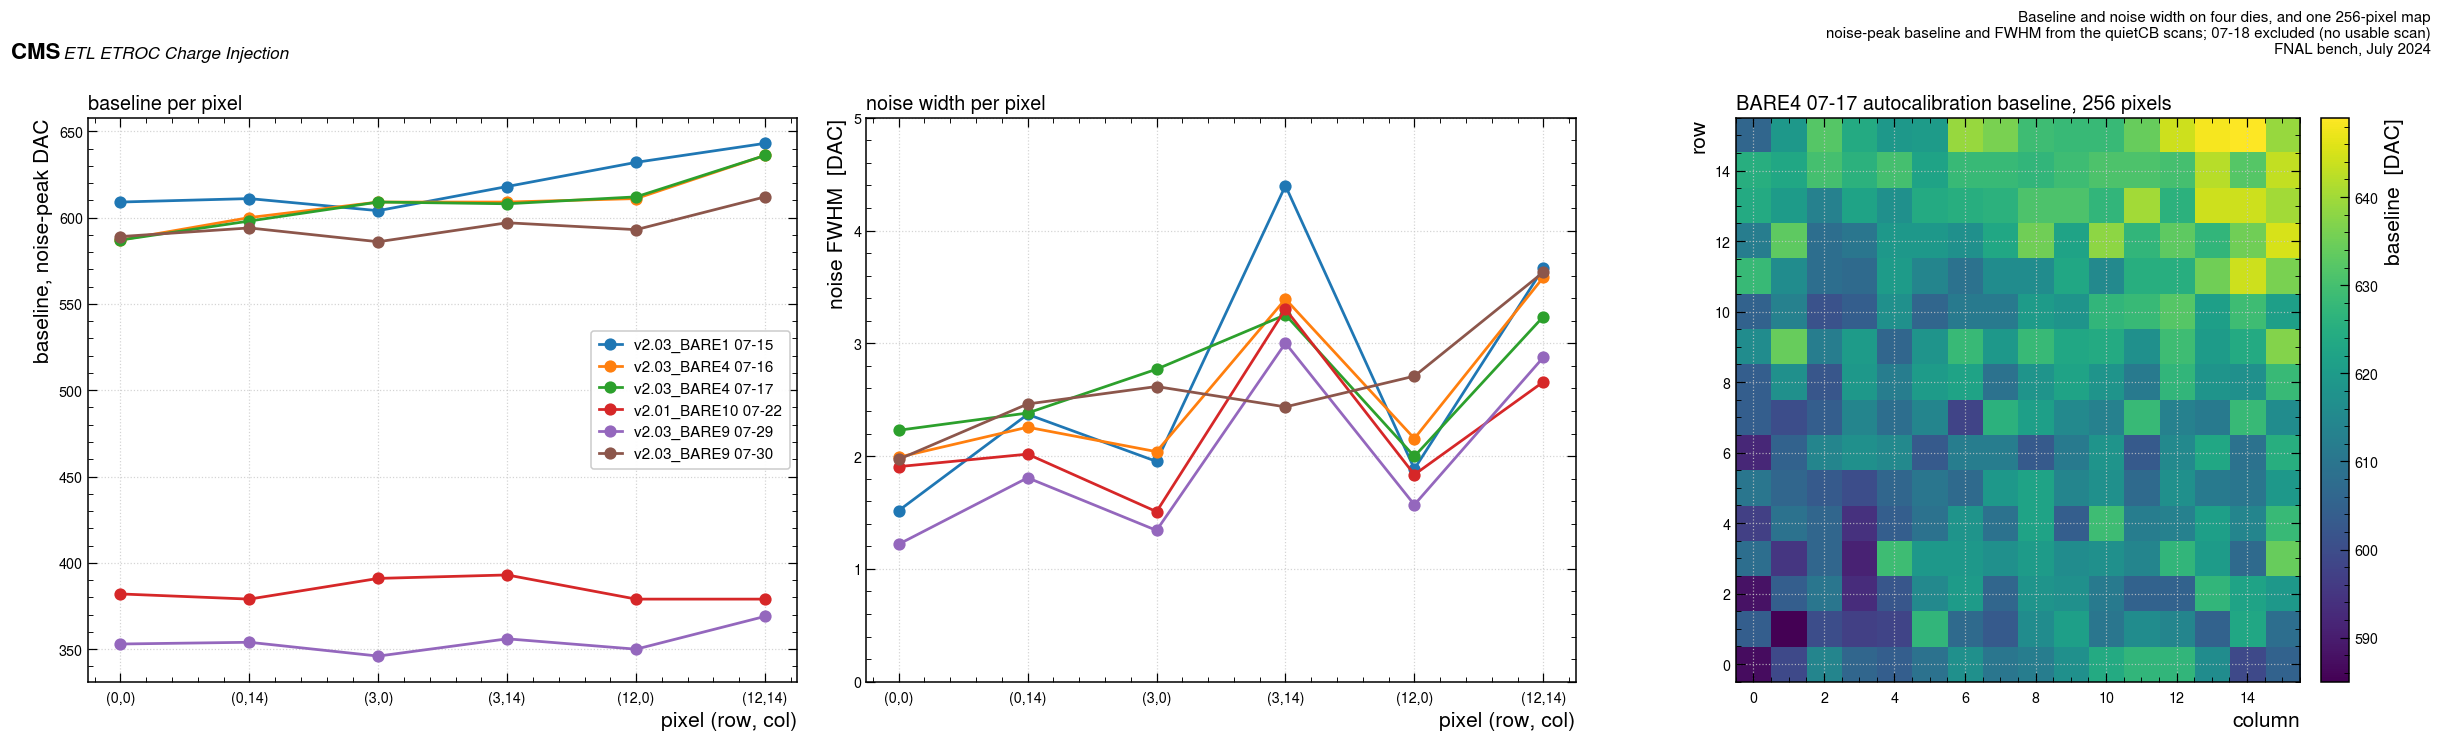

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.2))
ax = axs[0]
for i, acq in enumerate([a for a in ACQS if a != "v2.03_BARE4 07-18"]):
    g = NOI[NOI.acq == acq]
    ax.plot(range(6), [g[(g.row == r) & (g.col == c)].BL.iloc[0] for r, c in Q.JUL_PIXELS],
            "-o", lw=1.8, ms=7, label=acq, color=plt.cm.tab10(i))
ax.set_xticks(range(6))
ax.set_xticklabels(["(%d,%d)" % p for p in Q.JUL_PIXELS])
ax.set_xlabel("pixel (row, col)")
ax.set_ylabel("baseline, noise-peak DAC")
ax.legend(fontsize=10)
ax.set_title("baseline per pixel", loc="left", fontsize=13)
ax = axs[1]
for i, acq in enumerate([a for a in ACQS if a != "v2.03_BARE4 07-18"]):
    g = NOI[NOI.acq == acq]
    ax.plot(range(6), [g[(g.row == r) & (g.col == c)].fwhm.iloc[0] for r, c in Q.JUL_PIXELS],
            "-o", lw=1.8, ms=7, color=plt.cm.tab10(i))
ax.set_xticks(range(6))
ax.set_xticklabels(["(%d,%d)" % p for p in Q.JUL_PIXELS])
ax.set_xlabel("pixel (row, col)")
ax.set_ylabel("noise FWHM  [DAC]")
ax.set_ylim(0, 5)
ax.set_title("noise width per pixel", loc="left", fontsize=13)
ax = axs[2]
im = ax.imshow(MAP.pivot(index="row", columns="col", values="bl_dac").values, origin="lower", cmap="viridis")
ax.set_xlabel("column")
ax.set_ylabel("row")
ax.set_title("BARE4 07-17 autocalibration baseline, 256 pixels", loc="left", fontsize=13)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label="baseline  [DAC]")
fig.tight_layout()
Q.fig_header(fig, "Baseline and noise width on four dies, and one 256-pixel map",
             tag="noise-peak baseline and FWHM from the quietCB scans; 07-18 excluded (no usable scan)",
             scale=0.62, campaign=Q.JUL_CAMPAIGN)
Q.save_fig(fig, "jul_fig1_baselines")
plt.show()

## 4. Turn-off against charge, and the preamp gain of every pixel on every die

The turn-off is the discriminator binary search's own converged DAC (RAW), referred to the
noise-peak baseline of the same day and pixel. The preamp gain is `Q.gain_fit` over 9–28 fC, the
range and estimator of notebooks 01 and 02. Where 07-18 has no baseline the fit is still made
(the slope does not need one) and only the intercept is left undefined.

One thing the fit table says and the earlier notebooks did not dwell on: with the 0.5 DAC
y-error the straight line is rejected on every pixel of every acquisition (χ²/ndf 10–250 on
two degrees of freedom). The response is visibly convex over 9–28 fC — the 16–28 fC chord is
steeper than the 9–16 fC one by 10–20 % — so every "gain" in this folder is a **fixed-range
chord slope**, comparable between data sets only when the range is the same, and the
per-pixel fit errors in `jul_gain_fits.csv` are understated by √(χ²/ndf). The table carries
both the nominal error and the scaled one; section 7 is where the range matters.

In [8]:
TO = TOF.merge(NOI[["acq", "row", "col", "BL"]], on=["acq", "row", "col"], how="left")
TO["turnoff_offset"] = TO.turnoff_dac - TO.BL
TO["at_ceiling"] = TO.turnoff_dac >= 1019
print("turn-off above baseline [DAC], per acquisition, pixel and charge (07-18 has no baseline)")
print(TO.pivot_table(index=["acq", "charge_fC"], columns=["row", "col"], values="turnoff_offset").round(0).to_string())

gf = []
for (acq, r, c), g in TO.groupby(["acq", "row", "col"]):
    g = g[~g.at_ceiling]
    bl = float(g.BL.iloc[0]) if g.BL.notna().any() else np.nan
    f = Q.gain_fit(g, bl if np.isfinite(bl) else 0.0, q_lo=Q.JUL_QLO, q_hi=Q.JUL_QHI,
                   turnoff_col="turnoff_dac", charge_col="charge_fC")
    if not f:
        continue
    if not np.isfinite(bl):
        f["intercept_offset_dac"] = np.nan
        f["Qmin_at_off_fC"] = np.nan
    gf.append(dict(acq=acq, chip=DIE_OF[acq], row=r, col=c, BL=bl, **f))
GF = pd.DataFrame(gf)
GF["gain_err_scaled"] = GF.gain_dac_per_fc_err * np.sqrt(GF.chi2_ndf.clip(lower=1))
# the two chords, to make the convexity a number
ch = []
for (acq, r, c), g in TO.groupby(["acq", "row", "col"]):
    t = g.set_index("charge_fC").turnoff_dac
    if all(q in t.index for q in (9, 16, 28)) and not g.at_ceiling.any():
        ch.append(dict(acq=acq, row=r, col=c, chord_9_16=(t[16] - t[9]) / 7.0, chord_16_28=(t[28] - t[16]) / 12.0))
CH = pd.DataFrame(ch)
CH["convexity"] = CH.chord_16_28 / CH.chord_9_16
GF = GF.merge(CH, on=["acq", "row", "col"], how="left")
GF.to_csv(Q.OUTDIR / "jul_gain_fits.csv", index=False)
print("16-28 fC chord over 9-16 fC chord, the five pixels other than (0,14): median %.2f, range %.2f-%.2f"
      % (CH[~((CH.row == 0) & (CH.col == 14))].convexity.median(),
         CH[~((CH.row == 0) & (CH.col == 14))].convexity.min(), CH[~((CH.row == 0) & (CH.col == 14))].convexity.max()))
print("the same at (0,14): median %.2f" % CH[(CH.row == 0) & (CH.col == 14)].convexity.median())
print("fit error scaled by sqrt(chi2/ndf), median factor %.1f" % np.sqrt(GF.chi2_ndf.clip(lower=1)).median())
print("\npreamp gain [DAC/fC], 9-28 fC, per acquisition and pixel")
print(GF.pivot_table(index="acq", columns=["row", "col"], values="gain_dac_per_fc").reindex(ACQS).round(2).to_string())
print("\nchi2/ndf of the straight line")
print(GF.pivot_table(index="acq", columns=["row", "col"], values="chi2_ndf").reindex(ACQS).round(1).to_string())

turn-off above baseline [DAC], per acquisition, pixel and charge (07-18 has no baseline)
row                              0            3             12       
col                              0     14     0      14     0      14
acq                charge_fC                                         
v2.01_BARE10 07-22 6.0         30.0  18.0   38.0   27.0   31.0   22.0
                   7.0         45.0  23.0   44.0   36.0   41.0   30.0
                   9.0         62.0  36.0   69.0   53.0   58.0   48.0
                   16.0       145.0  58.0  151.0  124.0  136.0  115.0
                   23.0       242.0  71.0  229.0  198.0  229.0  195.0
                   28.0       288.0  81.0  283.0  244.0  276.0  253.0
v2.03_BARE1 07-15  6.0         15.0   6.0   31.0   21.0   24.0   29.0
                   7.0         23.0  12.0   41.0   28.0   33.0   40.0
                   9.0         34.0  25.0   57.0   40.0   51.0   57.0
                   16.0        98.0  57.0  135.0  103.0  120.0  135.0
 

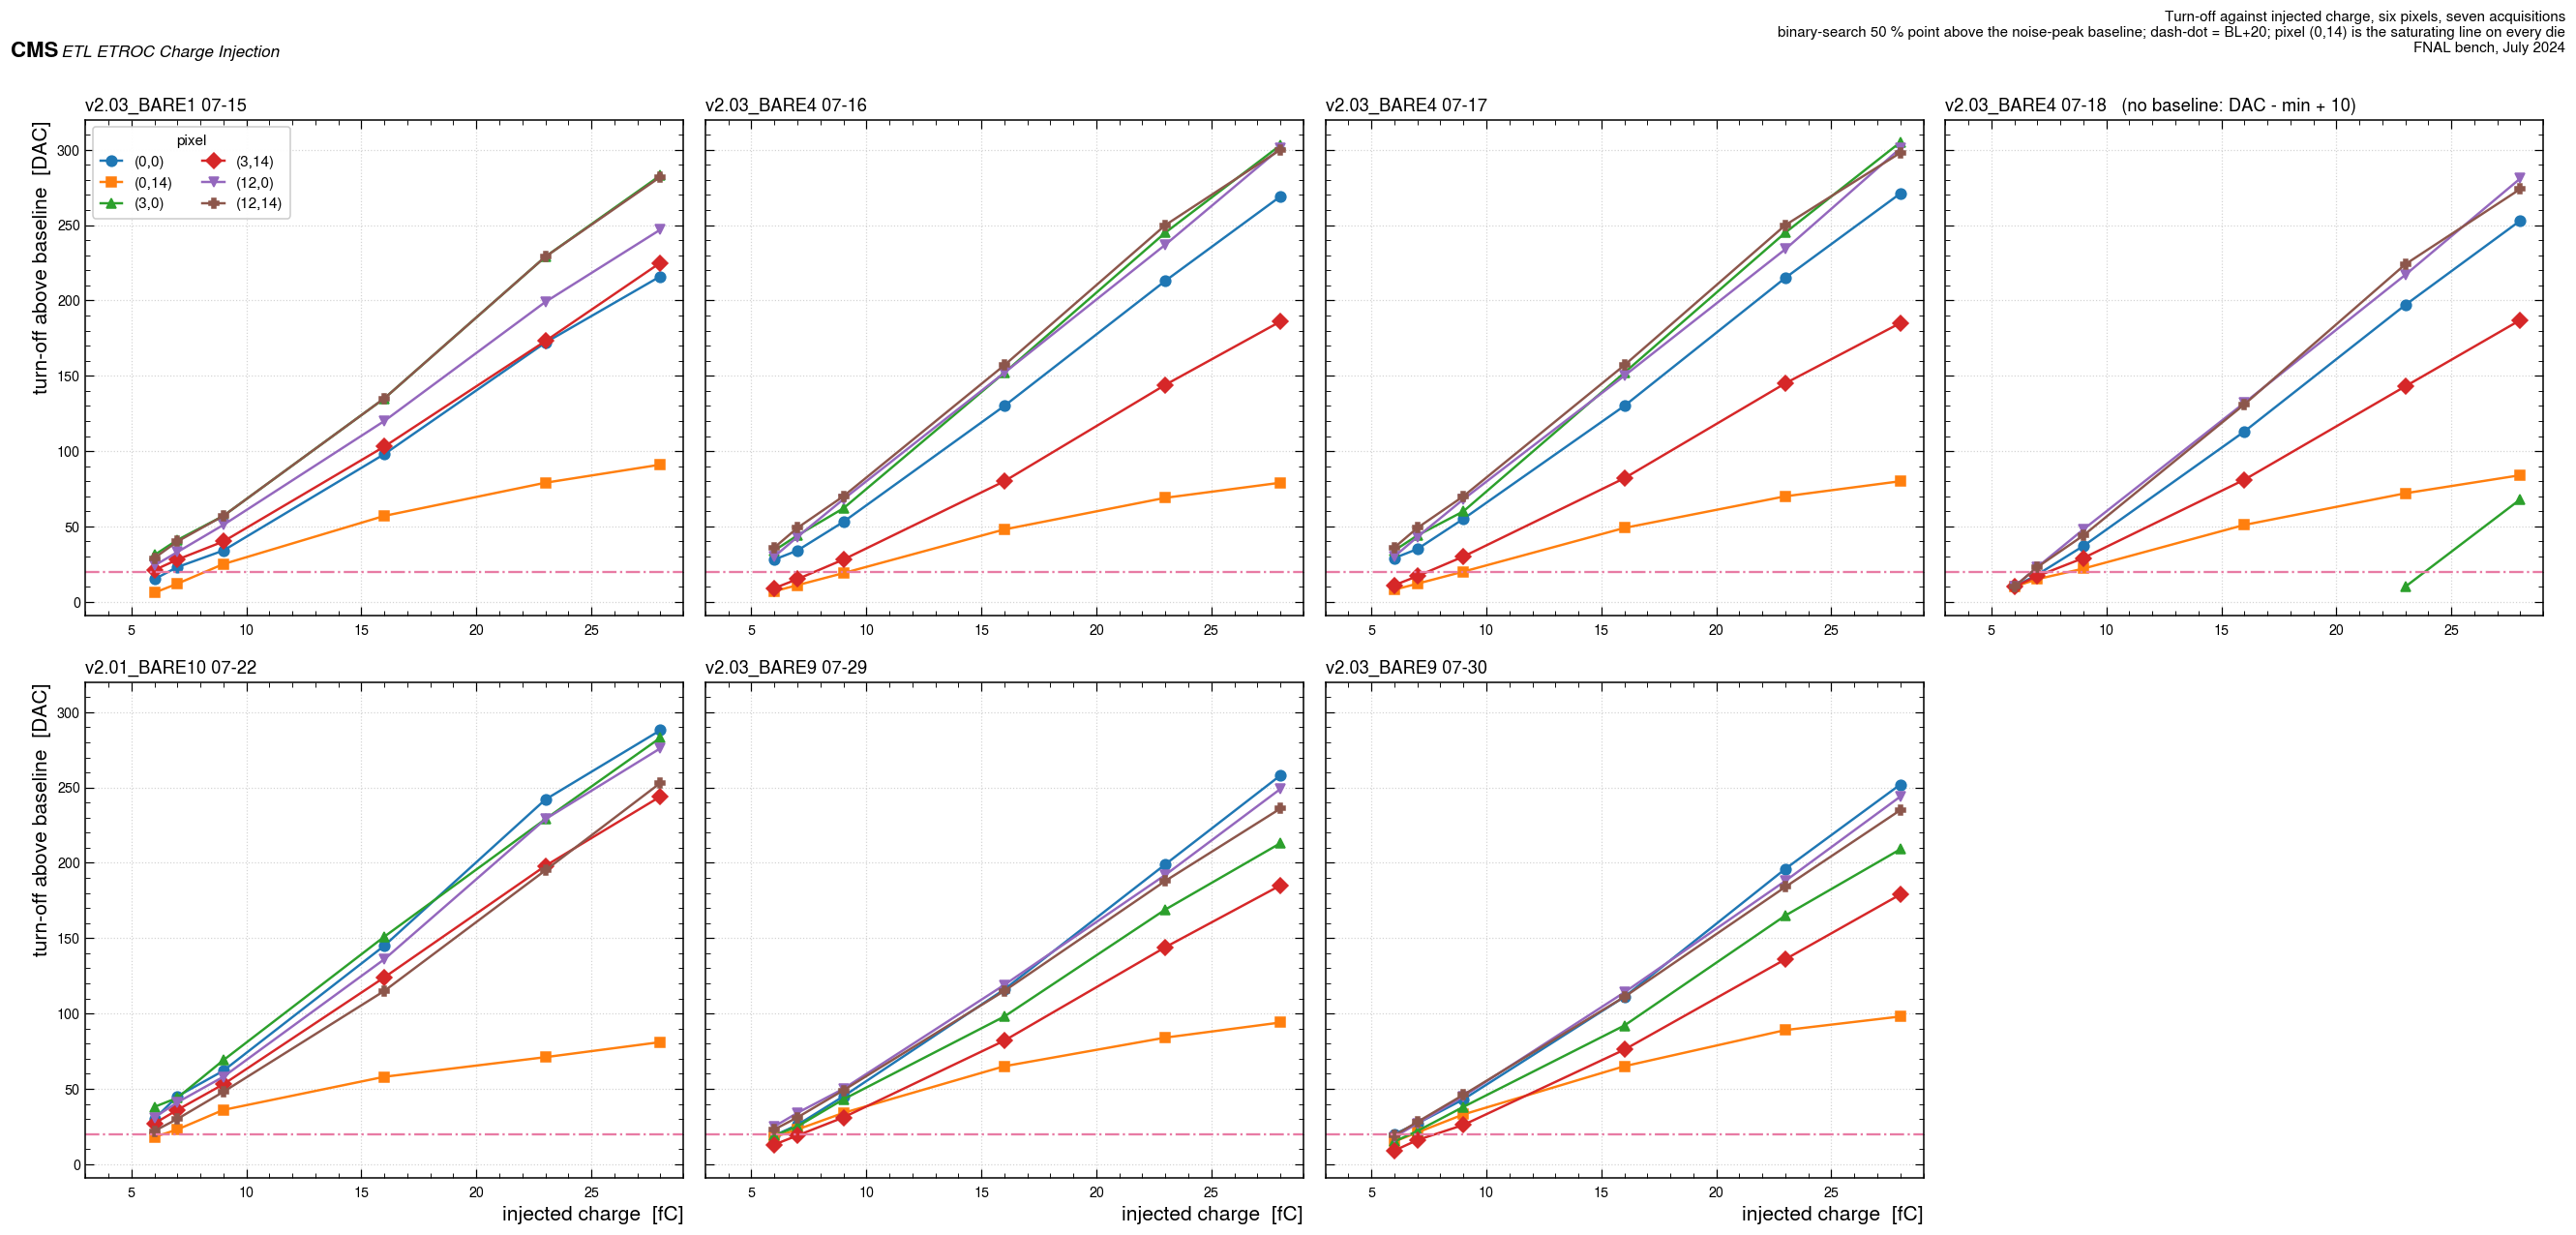

In [9]:
fig, axs = plt.subplots(2, 4, figsize=(24, 11), sharey=True)
PANELS = [a for a in ACQS]
PIXMK = ["o", "s", "^", "D", "v", "P"]      # pixel markers; Q.CMK is the folder's charge->marker map
for k, acq in enumerate(PANELS):
    ax = axs.flat[k]
    g = TO[(TO.acq == acq) & ~TO.at_ceiling]
    for i, (r, c) in enumerate(Q.JUL_PIXELS):
        s = g[(g.row == r) & (g.col == c)].sort_values("charge_fC")
        y = s.turnoff_offset if s.turnoff_offset.notna().any() else s.turnoff_dac - s.turnoff_dac.min() + 10
        ax.plot(s.charge_fC, y, "-", marker=PIXMK[i], ms=7, lw=1.6,
                color=plt.cm.tab10(i), label="(%d,%d)" % (r, c))
    ax.set_title(acq + ("   (no baseline: DAC - min + 10)" if acq == "v2.03_BARE4 07-18" else ""),
                 loc="left", fontsize=12)
    ax.axhline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=1.5)
    ax.set_xlim(3, 29)
    if k >= 4:
        ax.set_xlabel("injected charge  [fC]")
    if k % 4 == 0:
        ax.set_ylabel("turn-off above baseline  [DAC]")
    if k == 0:
        ax.legend(title="pixel", fontsize=10, title_fontsize=10, ncol=2)
axs.flat[7].axis("off")
fig.tight_layout()
Q.fig_header(fig, "Turn-off against injected charge, six pixels, seven acquisitions",
             tag="binary-search 50 % point above the noise-peak baseline; dash-dot = BL+20; pixel (0,14) is the saturating line on every die",
             scale=0.62, campaign=Q.JUL_CAMPAIGN)
Q.save_fig(fig, "jul_fig2_turnoff_vs_charge")
plt.show()

## 5. Pixel (0,14): a compressive response on six dies, and what the noise measurements can and cannot say

On every acquisition above, the (0,14) line is the one that bends over. At 6–9 fC it sits
close to the other pixels (on `BARE9` within 2 DAC at 6 fC); above 9 fC it falls away and
saturates at **80–100 DAC above baseline** while the other five reach 200–300. Fitted as a
chord over 9–28 fC that reads as a slope of 2.3–3.5 DAC/fC against 8.1–13.0, a ratio of about
0.3 — and it is the same pixel on `BARE1`, `BARE4`, `BARE9` and `BARE10` here, and, reading
notebooks 01, 02 and 03's own per-pixel fit tables, on `W36_6` (v2.01, January), `Bar4` (the
v2.01 hybrid, January) and `BARE9` again at every rail in August. Six dies, two revisions, three
sites, one pixel. Whatever it is, it is not a defect of a die.

The cell after the table tests the simplest reading, **a constant charge deficit at the
injector**: that would map the (0,14) curve onto the others' with one constant scale factor
*k*. It does not — the implied *k* drifts from ~0.7 at 9 fC to ~0.4 at 28 fC on every die (at
9 fC two of the six acquisitions, both `BARE4` days, put (0,14)'s turn-off below the others'
6 fC one, the lowest charge scanned, so their *k* is only an upper bound and is flagged
`clamped`; they are the two lowest values either way, so the 9 fC median over all six does not
depend on them), and
the local slope at (0,14) falls from 5–6 DAC/fC at 6–9 fC to ~2 at 23–28 fC while the other
pixels' rises. The response is **compressive**, not scaled. Two things could compress it: an
injection pulse whose amplitude saturates, or a front end whose output does. The noise
measurements are the discriminator between those, and they have to be read for what they can
resolve:

* The **256-pixel autocalibration noise width `NW`** is an integer with an array RMS of
  0.7–1.0 DAC on a mean of 3.5–4.4, so a single pixel's NW can exclude a 3× deficit of
  small-signal preamp gain but has no power below ~30 %. On four maps from four dies (`BARE4` here,
  `BARE9` in August, `W36_6` and `Bar4` in January) (0,14) reads 5, 4, 3 and 3 against array
  means of 3.8, 4.1, 3.5 and 4.4. So: **not a 3× small-signal deficit** — consistent with the
  near-normal turn-offs at 6–9 fC — and nothing finer.
* The **noise-scan FWHM** is finer, and its proper control is the other two column-14 pixels,
  because section 3 shows column 14 wider than column 0 on every die. Against that control
  (0,14) reads 0.6–0.8 (mean 0.68), and the shared S-curve width at (0,14) over 9–28 fC is
  0.40–0.72 (median 0.54) of the other five's. Both are what a front end whose output
  compresses would show at the operating point: noise projected onto the threshold axis
  through a shrinking local slope. A saturating injector with a normal front end would leave
  the small-signal FWHM alone. The weight is therefore on the **front end at (0,14) behaving
  differently**, not on the injector — and since the same DAQ software configured every one of
  the six dies, a per-pixel configuration difference (a front-end register that the software
  sets differently for that pixel) is the leading candidate. A register read-back at (0,14)
  settles it; none exists in any of these campaigns.

The consequence runs backwards through the folder regardless of cause. Notebooks 01–03 pooled
their gains over all scanned pixels, (0,14) included: with six pixels that pulls the mean down
by ~12 %, with twelve by ~6 %, and inflates the pixel-to-pixel RMS everywhere. The dose *ratios*
are paired per pixel and unaffected; the absolute gains, ENCs and pixel spreads are not, and
(0,14) should be excluded from them as an unrepresentative pixel of unresolved cause. The last
cell of this section recomputes each earlier campaign's pooled preamp gain with and without (0,14)
from the tables those notebooks wrote, so the size of the correction is a number rather than a
warning. In January's twelve pixels the whole of row 0 also reads low (column 8 at 0.7 of its
neighbours), so a position dependence is not confined to one corner; only (0,14) is common to
all campaigns and only it is treated here.

In [10]:
rows = []
for acq, g in GF.groupby("acq"):
    a = g[(g.row == 0) & (g.col == 14)].gain_dac_per_fc
    b = g[~((g.row == 0) & (g.col == 14))].gain_dac_per_fc
    rows.append(dict(campaign="FNAL bench Jul-2024", acquisition=acq, chip=DIE_OF[acq],
                     gain_0_14=float(a.iloc[0]) if len(a) else np.nan, gain_others=b.mean(),
                     others_rms=b.std(ddof=1), n_others=len(b)))
bj = pd.read_csv(Q.OUTDIR / "bare_gain_fits.csv")
for (d, t), g in bj.groupby(["dose", "temp"]):
    a = g[(g.row == 0) & (g.col == 14)].gain_dac_per_fc
    b = g[~((g.row == 0) & (g.col == 14))].gain_dac_per_fc
    rows.append(dict(campaign="CERN Jan-2024 TID (nb 01)", acquisition="%d MRad, %d C" % (d, t), chip="ET2p01_W36_6",
                     gain_0_14=float(a.iloc[0]) if len(a) else np.nan, gain_others=b.mean(),
                     others_rms=b.std(ddof=1), n_others=len(b)))
hj = pd.read_csv(Q.OUTDIR / "hybrid_gain_fits.csv")
for cfg, g in hj.groupby("config"):
    a = g[(g.row == 0) & (g.col == 14)].gain_dac_per_fc
    b = g[~((g.row == 0) & (g.col == 14))].gain_dac_per_fc
    if len(a) and len(b) >= 4:
        rows.append(dict(campaign="CERN Jan-2024 CC hybrid (nb 02)", acquisition=cfg, chip="ET2p01_Bar4",
                         gain_0_14=float(a.iloc[0]), gain_others=b.mean(), others_rms=b.std(ddof=1), n_others=len(b)))
ej = pd.read_csv(Q.OUTDIR / "et2p03_gain_fits.csv")
for cfg, g in ej[ej.chip == "ET2p03_BARE9"].groupby("config"):
    a = g[(g.row == 0) & (g.col == 14)].gain_dac_per_fc
    b = g[~((g.row == 0) & (g.col == 14))].gain_dac_per_fc
    if len(a) and len(b) >= 4:
        rows.append(dict(campaign="CERN Aug-2024 X-ray (nb 03)", acquisition=cfg, chip="ET2p03_BARE9",
                         gain_0_14=float(a.iloc[0]), gain_others=b.mean(), others_rms=b.std(ddof=1), n_others=len(b)))
P14 = pd.DataFrame(rows)
P14["ratio"] = P14.gain_0_14 / P14.gain_others
P14.to_csv(Q.OUTDIR / "jul_pixel_0_14_across_campaigns.csv", index=False)
print("pixel (0,14) against the mean of the other scanned pixels, every acquisition of every campaign in the folder\n")
print(P14.round(2).to_string(index=False))
print("\nratio (0,14) / others: median %.2f, range %.2f-%.2f over %d acquisitions on %d dies"
      % (P14.ratio.median(), P14.ratio.min(), P14.ratio.max(), len(P14), P14.chip.nunique()))
g14 = GF[(GF.row == 0) & (GF.col == 14)].gain_dac_per_fc
g5 = GF[~((GF.row == 0) & (GF.col == 14))].gain_dac_per_fc
print("July 9-28 fC chord slopes: (0,14) %.2f-%.2f DAC/fC, the other five %.2f-%.2f" % (g14.min(), g14.max(), g5.min(), g5.max()))
RESULTS["pixel_0_14_ratio_median"] = float(P14.ratio.median())
RESULTS["pixel_0_14_n_dies"] = int(P14.chip.nunique())

pixel (0,14) against the mean of the other scanned pixels, every acquisition of every campaign in the folder

                       campaign                                           acquisition          chip  gain_0_14  gain_others  others_rms  n_others  ratio
            FNAL bench Jul-2024                                    v2.01_BARE10 07-22 ET2p01_BARE10       2.33        11.22        0.79         5   0.21
            FNAL bench Jul-2024                                     v2.03_BARE1 07-15  ET2p03_BARE1       3.47        10.80        1.18         5   0.32
            FNAL bench Jul-2024                                     v2.03_BARE4 07-16  ET2p03_BARE4       3.17        11.42        1.76         5   0.28
            FNAL bench Jul-2024                                     v2.03_BARE4 07-17  ET2p03_BARE4       3.17        11.41        1.85         5   0.28
            FNAL bench Jul-2024                                     v2.03_BARE4 07-18  ET2p03_BARE4       3.26        11.08  

In [11]:
# Is (0,14) a constant charge deficit? Solve others(k*Q) = turnoff_0_14(Q) per charge by interpolation.
krows = []
for acq, g in TO[TO.acq != "v2.03_BARE4 07-18"].groupby("acq"):
    o = g[~((g.row == 0) & (g.col == 14))].groupby("charge_fC").turnoff_offset.mean()
    p = g[(g.row == 0) & (g.col == 14)].set_index("charge_fC").turnoff_offset
    for q in (9, 16, 23, 28):
        if q in p.index and np.isfinite(p[q]):
            k = np.interp(p[q], o.values, o.index.values) / q      # the charge at which the others cross (0,14)'s turn-off
            # np.interp clamps outside the others' scanned range: below their lowest-charge turn-off the
            # crossing charge reads as that lowest charge, so k is then an upper bound, not a measurement
            # (above their highest one it would be a lower bound). Such rows keep the clamp value and are
            # flagged `clamped`.
            side = "low" if p[q] <= o.iloc[0] else ("high" if p[q] >= o.iloc[-1] else "")
            krows.append(dict(acq=acq, charge_fC=q, turnoff_0_14=p[q], others_mean=o[q], implied_k=k,
                              clamped=bool(side), clamp_side=side))
    for lo, hi in ((6, 9), (23, 28)):
        if lo in p.index and hi in p.index:
            krows.append(dict(acq=acq, charge_fC=lo, chord=(hi - lo), local_slope_0_14=(p[hi] - p[lo]) / (hi - lo),
                              local_slope_others=(o[hi] - o[lo]) / (hi - lo)))
K14 = pd.DataFrame(krows)
K14.to_csv(Q.OUTDIR / "jul_pixel_0_14_constant_k_test.csv", index=False)
print("implied charge scale k = Q_others / Q at which the other pixels reach (0,14)'s turn-off:")
print(K14[K14.implied_k.notna()].pivot_table(index="acq", columns="charge_fC", values="implied_k").round(2).to_string())
KC = K14[K14.clamped.fillna(False).astype(bool)]
print("\nclamped (k is a bound, the interpolation sits at the end of the others' scanned range): %d of %d rows"
      % (len(KC), int(K14.implied_k.notna().sum())))
for _, r in KC.iterrows():
    print("  %s at %d fC: (0,14) turn-off %.1f DAC is %s the others' %s-charge turn-off, so k %s %.3f"
          % (r.acq, r.charge_fC, r.turnoff_0_14, "below" if r.clamp_side == "low" else "above",
             "lowest" if r.clamp_side == "low" else "highest", "<=" if r.clamp_side == "low" else ">=", r.implied_k))
print("\nlocal slope [DAC/fC] at (0,14) against the other five, 6-9 fC and 23-28 fC chords:")
print(K14[K14.local_slope_0_14.notna()].pivot_table(index="acq", columns="charge_fC", values=["local_slope_0_14", "local_slope_others"]).round(1).to_string())
sat = TO[(TO.row == 0) & (TO.col == 14) & (TO.charge_fC == 28) & TO.turnoff_offset.notna()]
print("\n(0,14) turn-off above baseline at 28 fC: %.0f-%.0f DAC on %d acquisitions; the other pixels: %.0f-%.0f"
      % (sat.turnoff_offset.min(), sat.turnoff_offset.max(), len(sat),
         TO[~((TO.row == 0) & (TO.col == 14)) & (TO.charge_fC == 28)].turnoff_offset.min(),
         TO[~((TO.row == 0) & (TO.col == 14)) & (TO.charge_fC == 28)].turnoff_offset.max()))
RESULTS["pixel_0_14_k_at_9"] = float(K14[K14.charge_fC == 9].implied_k.median())
RESULTS["pixel_0_14_k_at_28"] = float(K14[K14.charge_fC == 28].implied_k.median())
RESULTS["pixel_0_14_k_at_9_n_clamped"] = int(KC[KC.charge_fC == 9].shape[0])
RESULTS["pixel_0_14_k_at_28_n_clamped"] = int(KC[KC.charge_fC == 28].shape[0])

implied charge scale k = Q_others / Q at which the other pixels reach (0,14)'s turn-off:
charge_fC             9     16    23    28
acq                                       
v2.01_BARE10 07-22  0.74  0.56  0.44  0.40
v2.03_BARE1 07-15   0.68  0.62  0.53  0.47
v2.03_BARE4 07-16   0.67  0.51  0.44  0.39
v2.03_BARE4 07-17   0.67  0.51  0.44  0.40
v2.03_BARE9 07-29   0.87  0.71  0.59  0.52
v2.03_BARE9 07-30   0.91  0.74  0.64  0.56

clamped (k is a bound, the interpolation sits at the end of the others' scanned range): 2 of 24 rows
  v2.03_BARE4 07-16 at 9 fC: (0,14) turn-off 19.0 DAC is below the others' lowest-charge turn-off, so k <= 0.667
  v2.03_BARE4 07-17 at 9 fC: (0,14) turn-off 20.0 DAC is below the others' lowest-charge turn-off, so k <= 0.667

local slope [DAC/fC] at (0,14) against the other five, 6-9 fC and 23-28 fC chords:
                   local_slope_0_14      local_slope_others      
charge_fC                        6    23                 6     23
acq                    

/var/folders/st/45tl5ffn70sg25zsxp7lfsb40000gq/T/ipykernel_17372/4265377423.py:24: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  KC = K14[K14.clamped.fillna(False).astype(bool)]


In [12]:
# S-curve width at (0,14) against the other five, per July acquisition, and on W36_6 at 0 MRad
PRB = Q.et2p03_probes(TOF[TOF.acq != "v2.03_BARE4 07-18"], keys=("acq", "row", "col", "charge_fC"))
srows = []
for acq, g in PRB.groupby("acq"):
    g = g[g.charge_fC >= Q.JUL_QLO]
    for lab, m in [("(0,14)", (g.row == 0) & (g.col == 14)), ("other five", ~((g.row == 0) & (g.col == 14)))]:
        cur, _ = Q.curves_from(g[m], keys=("row", "col", "charge_fC"))
        s, sd, _, _ = Q.scurve_sigma(cur, boot=100)
        srows.append(dict(acquisition=acq, pixels=lab, n_curves=len(cur), sigma_dac=s, sigma_sd=sd))
bp = Q.load_bare_probes()
b0 = bp[(bp.dose == 0) & (bp.charge >= Q.JUL_QLO)]
for lab, m in [("(0,14)", (b0.row == 0) & (b0.col == 14)), ("other eleven", ~((b0.row == 0) & (b0.col == 14)))]:
    cur, _ = Q.curves_from(b0[m], keys=("temp", "row", "col", "charge"))
    s, sd, _, _ = Q.scurve_sigma(cur, boot=100)
    srows.append(dict(acquisition="W36_6 0 MRad (nb 01)", pixels=lab, n_curves=len(cur), sigma_dac=s, sigma_sd=sd))
S14 = pd.DataFrame(srows)
S14["pixels"] = S14.pixels.replace({"other eleven": "others", "other five": "others"})
sp = S14.pivot_table(index="acquisition", columns="pixels", values="sigma_dac")
sp["ratio"] = sp["(0,14)"] / sp["others"]
S14.to_csv(Q.OUTDIR / "jul_pixel_0_14_sigma.csv", index=False)
print("shared S-curve sigma [DAC], charges >= 9 fC")
print(sp.round(2).to_string())
jr = sp.loc[[a for a in sp.index if "W36_6" not in a], "ratio"]
print("\nJuly sigma ratio (0,14)/others: %.2f-%.2f, median %.2f" % (jr.min(), jr.max(), jr.median()))
# noise-scan FWHM at (0,14) against the column-14 control (3,14) and (12,14)
fw = NOI[NOI.acq != "v2.03_BARE4 07-18"]
f14 = fw[(fw.row == 0) & (fw.col == 14)].set_index("acq").fwhm
fc = fw[(fw.col == 14) & (fw.row != 0)].groupby("acq").fwhm.mean()
f00 = fw[(fw.row == 0) & (fw.col == 0)].set_index("acq").fwhm
FW = pd.DataFrame(dict(fwhm_0_14=f14, fwhm_col14_control=fc, fwhm_0_0=f00))
FW["ratio_to_col14"] = FW.fwhm_0_14 / FW.fwhm_col14_control
FW.to_csv(Q.OUTDIR / "jul_pixel_0_14_fwhm_control.csv")
print("\nnoise-scan FWHM [DAC] at (0,14) against the column-14 control:\n" + FW.round(2).to_string())
RESULTS["pixel_0_14_fwhm_ratio_col14"] = float(FW.ratio_to_col14.mean())
RESULTS["pixel_0_14_sigma_ratio_median"] = float(jr.median())

shared S-curve sigma [DAC], charges >= 9 fC
pixels                (0,14)  others  ratio
acquisition                                
W36_6 0 MRad (nb 01)    0.56    1.01   0.55
v2.01_BARE10 07-22      0.44    1.10   0.40
v2.03_BARE1 07-15       0.61    1.06   0.58
v2.03_BARE4 07-16       0.65    1.20   0.54
v2.03_BARE4 07-17       0.64    1.36   0.47
v2.03_BARE9 07-29       0.49    0.98   0.50
v2.03_BARE9 07-30       0.81    1.12   0.72

July sigma ratio (0,14)/others: 0.40-0.72, median 0.52

noise-scan FWHM [DAC] at (0,14) against the column-14 control:
                    fwhm_0_14  fwhm_col14_control  fwhm_0_0  ratio_to_col14
acq                                                                        
v2.01_BARE10 07-22       2.02                2.98      1.91            0.68
v2.03_BARE1 07-15        2.37                4.03      1.52            0.59
v2.03_BARE4 07-16        2.26                3.49      1.99            0.65
v2.03_BARE4 07-17        2.38                3.24      2.23 

In [13]:
# The four 256-pixel noise-width maps: is (0,14), row 0 or column 14 special?
maps = [("BARE4 (v2.03), 2024-07-17", MAP.rename(columns={"bl_dac": "bl", "nw_dac": "nw"}))]
am = Q.load_et2p03_tid_blnw()
maps.append(("BARE9 (v2.03), 2024-08-03", am[am.chip == "ET2p03_BARE9"].rename(columns={"baseline_DAC": "bl", "noise_width_DAC": "nw"})))
jb = Q.load_bare_blnw()
maps.append(("W36_6 (v2.01), %s" % jb.day.iloc[0], jb[jb.day == jb.day.iloc[0]].rename(columns={"baseline_dac": "bl", "noise_width_dac": "nw"})))
hb = Q.load_hybrid_blnw()
h0 = hb[(hb.day == hb.day.iloc[0]) & (hb.map_chip == hb.map_chip.iloc[0])]
h0 = h0.drop_duplicates(["row", "col"])
maps.append(("Bar4 hybrid (v2.01), %s" % hb.day.iloc[0][:10], h0.rename(columns={"baseline_dac": "bl", "noise_width_dac": "nw"})))
nw_rows = []
for name, m in maps:
    m = m[["row", "col", "bl", "nw"]].astype(float)
    nw_rows.append(dict(map=name, n=len(m), NW_mean=m.nw.mean(), NW_rms=m.nw.std(ddof=1),
                        NW_0_14=float(m[(m.row == 0) & (m.col == 14)].nw.iloc[0]),
                        NW_0_0=float(m[(m.row == 0) & (m.col == 0)].nw.iloc[0]),
                        NW_row0=m[m.row == 0].nw.mean(), NW_col14=m[m.col == 14].nw.mean(),
                        BL_row0_minus_row15=m[m.row == 0].bl.mean() - m[m.row == 15].bl.mean(),
                        BL_col0_minus_col15=m[m.col == 0].bl.mean() - m[m.col == 15].bl.mean()))
NWM = pd.DataFrame(nw_rows)
NWM.to_csv(Q.OUTDIR / "jul_nw_map_uniformity.csv", index=False)
print("autocalibration noise width NW [DAC] on four 256-pixel maps\n")
print(NWM.round(2).to_string(index=False))
NWM["NW_0_14_over_mean"] = NWM.NW_0_14 / NWM.NW_mean
print("\n(0,14) over the array mean, per map: %s" % ", ".join("%.2f" % v for v in NWM.NW_0_14_over_mean))
print("array RMS over mean, per map: %s  -> a one-pixel NW excludes a ~3x deficit, not a ~30 %% one"
      % ", ".join("%.2f" % v for v in NWM.NW_rms / NWM.NW_mean))
RESULTS["nw_maps_0_14_over_mean"] = float(NWM.NW_0_14_over_mean.mean())

autocalibration noise width NW [DAC] on four 256-pixel maps

                            map   n  NW_mean  NW_rms  NW_0_14  NW_0_0  NW_row0  NW_col14  BL_row0_minus_row15  BL_col0_minus_col15
      BARE4 (v2.03), 2024-07-17 256     3.77    0.66      5.0     4.0     3.75      4.00               -20.06               -20.81
      BARE9 (v2.03), 2024-08-03 256     4.10    1.04      4.0     3.0     4.06      3.81               -15.06                -9.69
      W36_6 (v2.01), 2024-01-11 256     3.53    1.05      3.0     3.0     3.44      3.50               -16.62                 9.75
Bar4 hybrid (v2.01), 2024-01-11 256     4.36    0.83      3.0     4.0     4.00      4.38               -33.19                -4.25

(0,14) over the array mean, per map: 1.33, 0.98, 0.85, 0.69
array RMS over mean, per map: 0.17, 0.25, 0.30, 0.19  -> a one-pixel NW excludes a ~3x deficit, not a ~30 % one


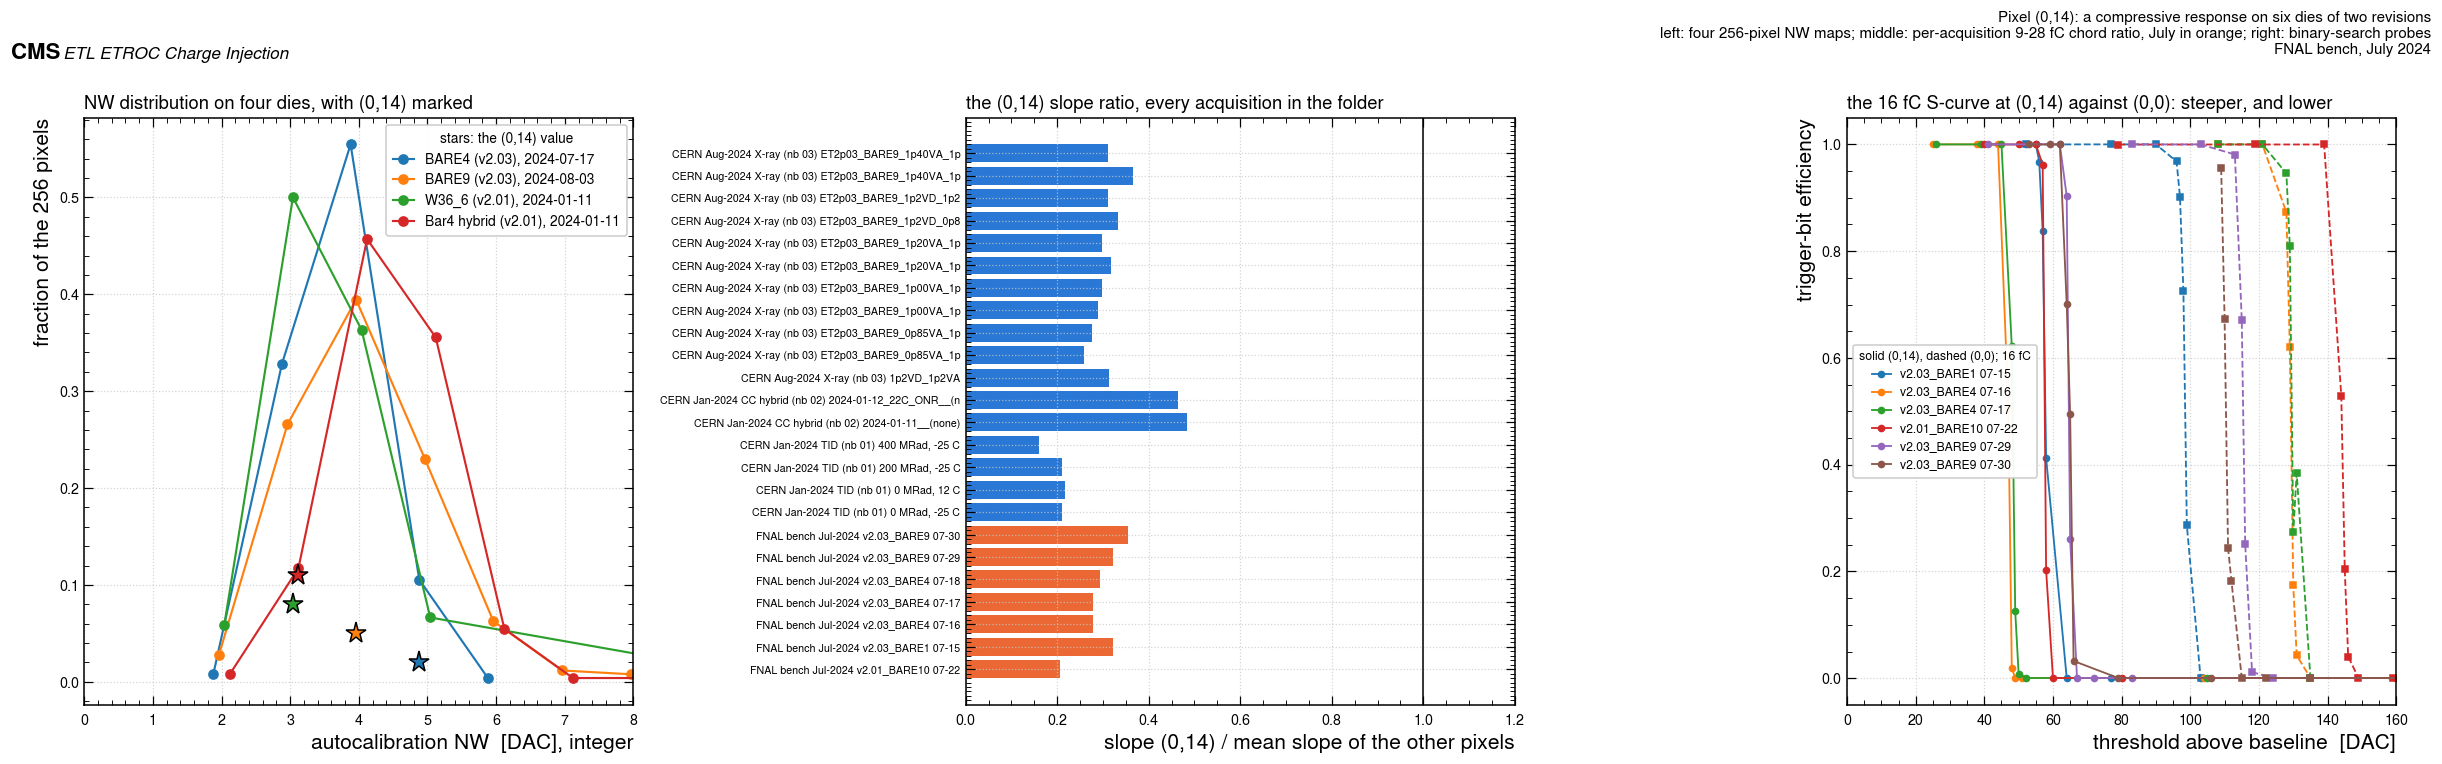

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
ax = axs[0]
for i, (name, m) in enumerate(maps):
    m = m[["row", "col", "nw"]].astype(float)
    vals, cnt = np.unique(m.nw.values, return_counts=True)
    ax.plot(vals + 0.08 * (i - 1.5), cnt / cnt.sum(), "-o", ms=6, lw=1.4, color=plt.cm.tab10(i), label=name)
    ax.plot([float(m[(m.row == 0) & (m.col == 14)].nw.iloc[0]) + 0.08 * (i - 1.5)], [0.02 + 0.03 * i], "*", ms=14,
            color=plt.cm.tab10(i), mec="black")
ax.set_xlim(0, 8)
ax.set_xlabel("autocalibration NW  [DAC], integer")
ax.set_ylabel("fraction of the 256 pixels")
ax.legend(fontsize=9, title="stars: the (0,14) value", title_fontsize=9)
ax.set_title("NW distribution on four dies, with (0,14) marked", loc="left", fontsize=12)
ax = axs[1]
lab = P14.campaign + " " + P14.acquisition.str.slice(0, 22)
ax.barh(range(len(P14)), P14.ratio, color=[Q.C_ORANGE if "Jul" in c else Q.C_BLUE for c in P14.campaign])
ax.set_yticks(range(len(P14)))
ax.set_yticklabels(lab, fontsize=7)
ax.axvline(1, color="black", lw=1)
ax.set_xlabel("slope (0,14) / mean slope of the other pixels")
ax.set_xlim(0, 1.2)
ax.set_title("the (0,14) slope ratio, every acquisition in the folder", loc="left", fontsize=12)
ax = axs[2]
for i, acq in enumerate([a for a in ACQS if a != "v2.03_BARE4 07-18"]):
    g = PRB[(PRB.acq == acq) & (PRB.row == 0) & (PRB.charge_fC == 16)]
    for (c, mk) in [(14, "o"), (0, "s")]:
        s = g[g.col == c].sort_values("dac")
        bl0 = BL.get((acq, 0, c), np.nan)
        ax.plot(s.dac - bl0, s.frac_c, "-" if c == 14 else "--", marker=mk, ms=4, lw=1.2,
                color=plt.cm.tab10(i), label=(acq if c == 14 else None))
ax.set_xlabel("threshold above baseline  [DAC]")
ax.set_ylabel("trigger-bit efficiency")
ax.set_xlim(0, 160)
ax.legend(fontsize=8, title="solid (0,14), dashed (0,0); 16 fC", title_fontsize=8)
ax.set_title("the 16 fC S-curve at (0,14) against (0,0): steeper, and lower", loc="left", fontsize=12)
fig.tight_layout()
Q.fig_header(fig, "Pixel (0,14): a compressive response on six dies of two revisions",
             tag="left: four 256-pixel NW maps; middle: per-acquisition 9-28 fC chord ratio, July in orange; right: binary-search probes",
             scale=0.62, campaign=Q.JUL_CAMPAIGN)
Q.save_fig(fig, "jul_fig3_pixel_0_14")
plt.show()

In [15]:
# The pooled gains of notebooks 01-03, with and without (0,14), from their own per-pixel tables
prow = []
for (d, t), g in bj.groupby(["dose", "temp"]):
    prow.append(dict(notebook="01 W36_6", condition="%d MRad, %d C" % (d, t),
                     gain_all=g.gain_dac_per_fc.mean(), rms_all=g.gain_dac_per_fc.std(ddof=1), n_all=len(g),
                     gain_excl=g[~((g.row == 0) & (g.col == 14))].gain_dac_per_fc.mean(),
                     rms_excl=g[~((g.row == 0) & (g.col == 14))].gain_dac_per_fc.std(ddof=1)))
for cfg, g in hj.groupby("config"):
    if len(g) < 6:
        continue
    prow.append(dict(notebook="02 Bar4 hybrid", condition=cfg,
                     gain_all=g.gain_dac_per_fc.mean(), rms_all=g.gain_dac_per_fc.std(ddof=1), n_all=len(g),
                     gain_excl=g[~((g.row == 0) & (g.col == 14))].gain_dac_per_fc.mean(),
                     rms_excl=g[~((g.row == 0) & (g.col == 14))].gain_dac_per_fc.std(ddof=1)))
for cfg, g in ej[ej.chip == "ET2p03_BARE9"].groupby("config"):
    prow.append(dict(notebook="03 BARE9", condition=cfg,
                     gain_all=g.gain_dac_per_fc.mean(), rms_all=g.gain_dac_per_fc.std(ddof=1), n_all=len(g),
                     gain_excl=g[~((g.row == 0) & (g.col == 14))].gain_dac_per_fc.mean(),
                     rms_excl=g[~((g.row == 0) & (g.col == 14))].gain_dac_per_fc.std(ddof=1)))
for acq, g in GF.groupby("acq"):
    prow.append(dict(notebook="05 " + acq, condition="bench",
                     gain_all=g.gain_dac_per_fc.mean(), rms_all=g.gain_dac_per_fc.std(ddof=1), n_all=len(g),
                     gain_excl=g[~((g.row == 0) & (g.col == 14))].gain_dac_per_fc.mean(),
                     rms_excl=g[~((g.row == 0) & (g.col == 14))].gain_dac_per_fc.std(ddof=1)))
POOL = pd.DataFrame(prow)
POOL["excl_over_all"] = POOL.gain_excl / POOL.gain_all
POOL.to_csv(Q.OUTDIR / "jul_pooled_gain_with_without_0_14.csv", index=False)
print("pooled preamp gain [DAC/fC] with and without pixel (0,14)\n")
print(POOL.round(2).to_string(index=False))
RESULTS["pooled_gain_bias_6px"] = float(POOL[POOL.n_all == 6].excl_over_all.median())
RESULTS["pooled_gain_bias_12px"] = float(POOL[POOL.n_all == 12].excl_over_all.median()) if (POOL.n_all == 12).any() else np.nan
print("\nexcluding (0,14) raises a six-pixel pooled preamp gain by a median factor %.3f and a twelve-pixel one by %.3f"
      % (RESULTS["pooled_gain_bias_6px"], RESULTS["pooled_gain_bias_12px"]))

pooled preamp gain [DAC/fC] with and without pixel (0,14)

             notebook                                             condition  gain_all  rms_all  n_all  gain_excl  rms_excl  excl_over_all
             01 W36_6                                         0 MRad, -25 C      8.69     2.98     12       9.30      2.20           1.07
             01 W36_6                                          0 MRad, 12 C      9.42     3.09     12      10.07      2.19           1.07
             01 W36_6                                       200 MRad, -25 C      8.31     2.86     12       8.90      2.12           1.07
             01 W36_6                                       400 MRad, -25 C      8.22     2.86     12       8.83      1.99           1.08
       02 Bar4 hybrid                                    2024-01-11__(none)      4.06     1.35      9       4.53      0.99           1.12
       02 Bar4 hybrid                            2024-01-12_22C_ONR__(none)      4.44     1.16      9       4.72 

## 6. v2.01 against v2.03 on the same bench

From here on every pooled number is over the **five pixels other than (0,14)**, and the
per-pixel comparison between dies is made pixel by pixel.

The question notebook 04 could not settle is whether the threshold-DAC scale follows the
reference voltage. If the DAC full scale is proportional to VRef and the front ends of the two
revisions are the same circuit at the same rail and registers, then a v2.01 die on its external
1.0 V reference should read a slope **0.86–0.89 ×** that of a v2.03 die on its internal
reference, because the internal reference measures 0.86–0.89 V (notebook 03 section 15, `BARE9`
at −23 °C; notebook 00 section 7.6, `BARE4` at 0 °C plus its +0.57 mV/°C; 0.891 V is used for
the line below, `BARE4` extrapolated to ~22 °C) — a larger LSB, fewer DAC per fC. The S-curve
width and the noise FWHM in DAC would scale the same way, and the ENC would not move at all.

What the bench shows is mixed, and it is reported as mixed. The v2.01 die's **slope** and
**S-curve width** sit inside the die-to-die spread of the three v2.03 dies with ratios near
1.0; its **noise FWHM** ratio lands on the VRef prediction (0.88) rather than on 1.0. Three
observables, two of which favour one reading and one the other. Two caveats make the slope
result weaker than its error bar: the error is a spread over three v2.03 dies (two degrees of
freedom) applied to one v2.01 die, so the 1.7 σ is a Student-t on 2 dof, about 1.2 σ in
Gaussian terms; and **the analog rail was hand-set and unrecorded on every day**. Notebook 03's
rail scan gives d ln(preamp gain)/dVA ≈ 2.5 per volt at this operating point, so the whole gap
between the observed 1.05 and the predicted 0.89 corresponds to ~65 mV of supply difference
between the 07-22 setup and the v2.03 days — well inside what a bench supply set by hand can
differ by. This comparison therefore **cannot resolve** the DAC-scale question on its own; it
fixes the size of the rail systematic that the transfer-function measurement (the bench
plan's first item, with the rail and the registers read back) must control. What does
survive is narrower: the two `BARE4` days and the two `BARE9` days reproduce each other's slope
to 0.1 %, so the 8 % spread among the v2.03 dies is a genuine die-to-die spread and not a
day-to-day one.

In [16]:
VREF_INT_V = 0.891     # BARE4 in the chamber, 0.878 V at 0 C, +0.573 mV/C to ~22 C (notebook 00, 7.6)
VREF_INT_BAND = (0.864, 0.891)   # BARE9 at -23 C (notebook 03, 15) to BARE4 at ~22 C
VREF_EXT_V = 1.000     # the external reference of the v2.01 boards
PRED_RATIO = VREF_INT_V / VREF_EXT_V
PRED_BAND = (VREF_INT_BAND[0] / VREF_EXT_V, VREF_INT_BAND[1] / VREF_EXT_V)
# the rail sensitivity of the chord slope, from notebook 03's BARE9 0 MRad rail scan (supply 0.85 -> 1.20 V)
_rs = pd.read_csv(Q.OUTDIR / "et2p03_gain_by_condition.csv")
_rs = _rs[(_rs.chip == "ET2p03_BARE9") & (_rs.dose == 0)].set_index("va").gain_dac_per_fc
DLNG_DVA = float(np.log(_rs[1.20] / _rs[0.85]) / (1.20 - 0.85))
print("d ln(preamp gain)/dVA from notebook 03's rail scan: %.2f per volt (BARE9, 0 MRad, supply 0.85 -> 1.20 V)" % DLNG_DVA)
G5 = GF[~((GF.row == 0) & (GF.col == 14))]
die_rows = []
for acq in ACQS:
    g = G5[G5.acq == acq]
    p = Q.pooled(g.gain_dac_per_fc)
    n = NOI[NOI.acq == acq]
    n5 = n[~((n.row == 0) & (n.col == 14))]
    pr = PRB[(PRB.acq == acq) & (PRB.charge_fC >= Q.JUL_QLO) & ~((PRB.row == 0) & (PRB.col == 14))]
    if len(pr):
        cur, _ = Q.curves_from(pr, keys=("row", "col", "charge_fC"))
        s, sd, _, _ = Q.scurve_sigma(cur, boot=100)
    else:
        s, sd, cur = np.nan, np.nan, []
    die_rows.append(dict(acquisition=acq, chip=DIE_OF[acq], revision=DIE_OF[acq][:6].replace("ET2p0", "v2.0"),
                         n_pixels=p["n"], gain_dac_per_fc=p["mean"], gain_sem=p["sem"], gain_pixel_rms=p["rms"],
                         BL_mean=n5.BL.mean(), fwhm_mean=n5.fwhm.mean(), fwhm_rms=n5.fwhm.std(ddof=1),
                         n_curves=len(cur), sigma_dac=s, sigma_sd=sd,
                         ENC_e=Q.enc_electrons(s, p["mean"]) if np.isfinite(s) else np.nan))
DIE = pd.DataFrame(die_rows)
DIE.to_csv(Q.OUTDIR / "jul_gain_by_die.csv", index=False)
print("per acquisition, five pixels (excluding (0,14)):\n")
print(DIE.round(2).to_string(index=False))

d ln(preamp gain)/dVA from notebook 03's rail scan: 2.49 per volt (BARE9, 0 MRad, supply 0.85 -> 1.20 V)
per acquisition, five pixels (excluding (0,14)):

       acquisition          chip revision  n_pixels  gain_dac_per_fc  gain_sem  gain_pixel_rms  BL_mean  fwhm_mean  fwhm_rms  n_curves  sigma_dac  sigma_sd  ENC_e
 v2.03_BARE1 07-15  ET2p03_BARE1    v2.03         5            10.80      0.53            1.18    621.2       2.68      1.27        20       1.06      0.08 612.70
 v2.03_BARE4 07-16  ET2p03_BARE4    v2.03         5            11.42      0.79            1.76    610.4       2.63      0.79        20       1.20      0.08 655.77
 v2.03_BARE4 07-17  ET2p03_BARE4    v2.03         5            11.41      0.83            1.85    610.4       2.70      0.57        20       1.36      0.10 743.90
 v2.03_BARE4 07-18  ET2p03_BARE4    v2.03         4            11.08      0.93            1.85      NaN        NaN       NaN         0        NaN       NaN    NaN
v2.01_BARE10 07-22 ET2p01_BARE

In [17]:
ok = DIE[DIE.acquisition != "v2.03_BARE4 07-18"]
v203 = ok[ok.revision == "v2.03"].groupby("chip").agg(gain=("gain_dac_per_fc", "mean"), sigma=("sigma_dac", "mean"),
                                                        fwhm=("fwhm_mean", "mean"), ENC=("ENC_e", "mean"))
v201 = ok[ok.revision == "v2.01"].iloc[0]
print("v2.03 dies, day-averaged:\n" + v203.round(2).to_string())
print("\nv2.01 BARE10: preamp gain %.2f, sigma %.2f, FWHM %.2f, ENC %.0f" % (v201.gain_dac_per_fc, v201.sigma_dac, v201.fwhm_mean, v201.ENC_e))
r_gain = v201.gain_dac_per_fc / v203.gain.mean()
r_gain_err = r_gain * np.sqrt((v203.gain.std(ddof=1) / np.sqrt(len(v203)) / v203.gain.mean()) ** 2
                              + (v203.gain.std(ddof=1) / v203.gain.mean()) ** 2)   # the one v2.01 die gets the v2.03 spread
r_sig = v201.sigma_dac / v203.sigma.mean()
r_fwhm = v201.fwhm_mean / v203.fwhm.mean()
r_fwhm_err = r_fwhm * np.sqrt((v203.fwhm.std(ddof=1) / v203.fwhm.mean()) ** 2 + (v203.fwhm.std(ddof=1) / np.sqrt(len(v203)) / v203.fwhm.mean()) ** 2)
r_enc = v201.ENC_e / v203.ENC.mean()
r_enc_err = r_enc * np.sqrt((v203.ENC.std(ddof=1) / v203.ENC.mean()) ** 2 + (v203.ENC.std(ddof=1) / np.sqrt(len(v203)) / v203.ENC.mean()) ** 2)
# pixel-by-pixel: BARE10 against the mean of the three v2.03 dies at the same pixel
pp = G5.groupby(["chip", "row", "col"]).gain_dac_per_fc.mean().unstack("chip")
pp = pp[pp.index.get_level_values(0).notna()]
pp["v2.03_mean"] = pp[["ET2p03_BARE1", "ET2p03_BARE4", "ET2p03_BARE9"]].mean(axis=1)
pp["ratio_2p01_over_2p03"] = pp["ET2p01_BARE10"] / pp["v2.03_mean"]
print("\npixel by pixel, day-averaged preamp gain [DAC/fC]:\n" + pp.round(2).to_string())
REV = pd.DataFrame([
    dict(quantity="preamp gain, v2.01 / mean v2.03", observed=r_gain, err=r_gain_err,
         predicted_if_DAC_follows_VRef=PRED_RATIO, predicted_if_same_scale=1.0),
    dict(quantity="preamp gain, pixel-by-pixel median ratio", observed=pp.ratio_2p01_over_2p03.median(),
         # the pixel-wise ratio removes the injection gradient but not the one v2.01 die's own place in the die-to-die spread
         err=np.hypot(pp.ratio_2p01_over_2p03.std(ddof=1) / np.sqrt(len(pp)),
                      pp.ratio_2p01_over_2p03.median() * v203.gain.std(ddof=1) / v203.gain.mean()),
         predicted_if_DAC_follows_VRef=PRED_RATIO, predicted_if_same_scale=1.0),
    dict(quantity="S-curve sigma, v2.01 / mean v2.03", observed=r_sig, err=r_sig * np.sqrt((v201.sigma_sd / v201.sigma_dac) ** 2 + (v203.sigma.std(ddof=1) / v203.sigma.mean()) ** 2),
         predicted_if_DAC_follows_VRef=PRED_RATIO, predicted_if_same_scale=1.0),
    dict(quantity="noise FWHM, v2.01 / mean v2.03", observed=r_fwhm, err=r_fwhm_err,
         predicted_if_DAC_follows_VRef=PRED_RATIO, predicted_if_same_scale=1.0),
    dict(quantity="ENC, v2.01 / mean v2.03", observed=r_enc, err=r_enc_err,
         predicted_if_DAC_follows_VRef=1.0, predicted_if_same_scale=1.0),
])
from scipy import stats
REV["t_from_VRef_prediction"] = (REV.observed - REV.predicted_if_DAC_follows_VRef) / REV.err
REV["t_from_same_scale"] = (REV.observed - REV.predicted_if_same_scale) / REV.err
# the die spread comes from three dies: two degrees of freedom, so read t on a Student-t(2)
REV["gauss_sigma_equiv_VRef"] = stats.norm.isf(stats.t.sf(REV.t_from_VRef_prediction.abs(), df=2))
REV["rail_equiv_mV"] = 1e3 * np.log(REV.observed / REV.predicted_if_DAC_follows_VRef) / DLNG_DVA
REV.loc[REV.quantity.str.startswith("ENC"), "rail_equiv_mV"] = np.nan
V_PER_FC_RATIO = r_gain / PRED_RATIO
REV.to_csv(Q.OUTDIR / "jul_revision_comparison.csv", index=False)
print("\nv2.01 against v2.03 on the same bench (predicted ratio %.3f if the DAC scale follows VRef, %.3f V / %.3f V)\n"
      % (PRED_RATIO, VREF_INT_V, VREF_EXT_V))
print(REV.round(3).to_string(index=False))
print("\nif the DAC scale does follow VRef (band %.3f-%.3f), the v2.01 front end delivers %.2f x the v2.03 volts per fC"
      % (PRED_BAND[0], PRED_BAND[1], V_PER_FC_RATIO))
print("the preamp gain gap 1.05 vs %.3f is equivalent to %.0f mV of analog-supply difference at d ln(preamp gain)/dVA = %.2f /V; the rail was not recorded"
      % (PRED_RATIO, REV.rail_equiv_mV.iloc[0], DLNG_DVA))
RESULTS["rev_gain_rail_equiv_mV"] = float(REV.rail_equiv_mV.iloc[0])
RESULTS["rev_gain_gauss_sigma_equiv"] = float(REV.gauss_sigma_equiv_VRef.iloc[0])
RESULTS["rev_v_per_fc_ratio_if_vref"] = float(V_PER_FC_RATIO)
RESULTS["rev_fwhm_ratio"] = float(r_fwhm)
RESULTS["rev_gain_ratio"] = float(r_gain)
RESULTS["rev_gain_ratio_err"] = float(r_gain_err)
RESULTS["rev_pred_ratio_vref"] = float(PRED_RATIO)
RESULTS["rev_sigma_ratio"] = float(r_sig)

v2.03 dies, day-averaged:
               gain  sigma  fwhm     ENC
chip                                    
ET2p03_BARE1  10.80   1.06  2.68  612.70
ET2p03_BARE4  11.42   1.28  2.66  699.84
ET2p03_BARE9   9.77   1.05  2.34  670.95

v2.01 BARE10: preamp gain 11.22, sigma 1.10, FWHM 2.24, ENC 612

pixel by pixel, day-averaged preamp gain [DAC/fC]:
chip     ET2p01_BARE10  ET2p03_BARE1  ET2p03_BARE4  ET2p03_BARE9  v2.03_mean  ratio_2p01_over_2p03
row col                                                                                           
0   0            12.16          9.70         11.44         11.19       10.77                  1.13
3   0            11.26         12.08         12.86          9.11       11.35                  0.99
    14           10.13          9.75          8.33          8.14        8.74                  1.16
12  0            11.71         10.43         12.23         10.46       11.04                  1.06
    14           10.83         12.03         12.25        


v2.01 against v2.03 on the same bench (predicted ratio 0.891 if the DAC scale follows VRef, 0.891 V / 1.000 V)

                                quantity  observed   err  predicted_if_DAC_follows_VRef  predicted_if_same_scale  t_from_VRef_prediction  t_from_same_scale  gauss_sigma_equiv_VRef  rail_equiv_mV
         preamp gain, v2.01 / mean v2.03     1.052 0.095                          0.891                      1.0                   1.700              0.551                   1.197         66.853
preamp gain, pixel-by-pixel median ratio     1.061 0.092                          0.891                      1.0                   1.849              0.661                   1.265         70.034
       S-curve sigma, v2.01 / mean v2.03     0.973 0.124                          0.891                      1.0                   0.665             -0.214                   0.561         35.556
          noise FWHM, v2.01 / mean v2.03     0.875 0.077                          0.891                    

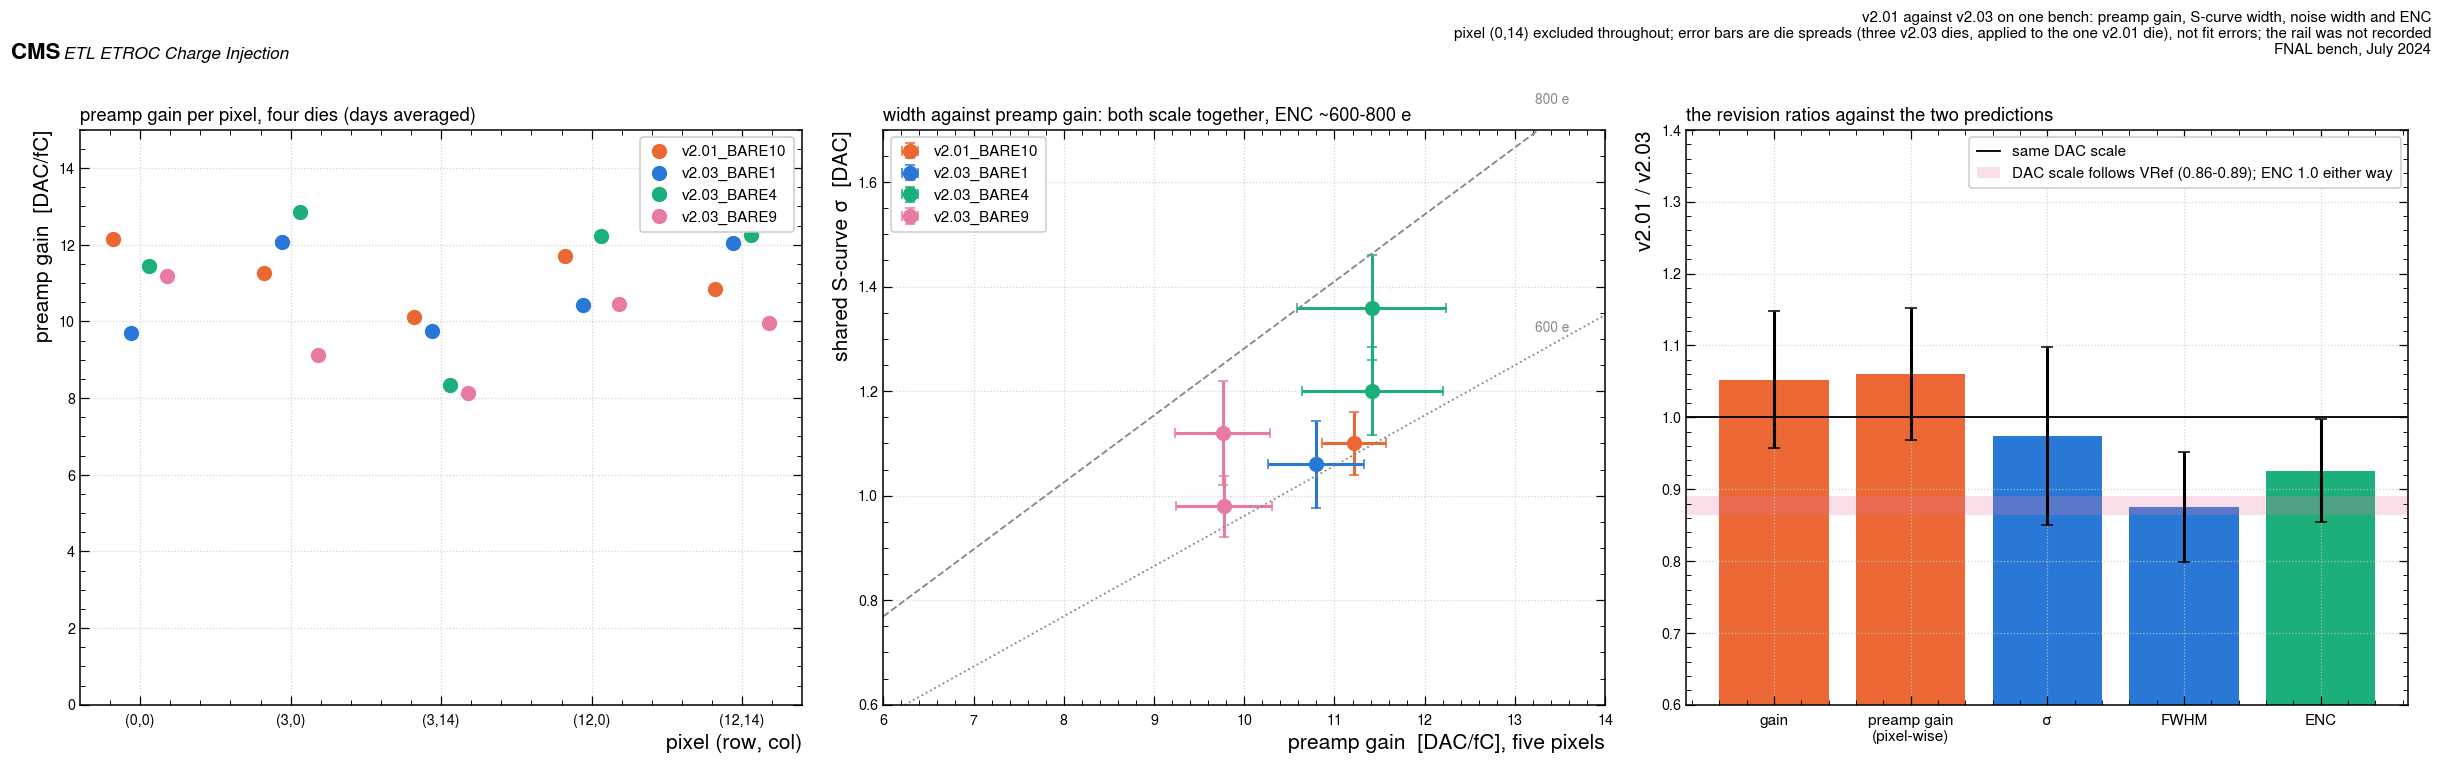

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
ax = axs[0]
chips = ["ET2p01_BARE10", "ET2p03_BARE1", "ET2p03_BARE4", "ET2p03_BARE9"]
cols = {"ET2p01_BARE10": Q.C_ORANGE, "ET2p03_BARE1": Q.C_BLUE, "ET2p03_BARE4": Q.C_AQUA, "ET2p03_BARE9": Q.C_MAG}
pix5 = [p for p in Q.JUL_PIXELS if p != (0, 14)]
for k, ch in enumerate(chips):
    g = G5[G5.chip == ch].groupby(["row", "col"]).gain_dac_per_fc.agg(["mean", "std", "count"])
    y = [g.loc[p, "mean"] if p in g.index else np.nan for p in pix5]
    ax.plot(np.arange(5) + 0.12 * (k - 1.5), y, "o", ms=9, color=cols[ch], label=ch.replace("ET2p0", "v2.0"))
ax.set_xticks(range(5))
ax.set_xticklabels(["(%d,%d)" % p for p in pix5])
ax.set_xlabel("pixel (row, col)")
ax.set_ylabel("preamp gain  [DAC/fC]")
ax.set_ylim(0, 15)
ax.legend(fontsize=10)
ax.set_title("preamp gain per pixel, four dies (days averaged)", loc="left", fontsize=12)
ax = axs[1]
o = DIE[DIE.acquisition != "v2.03_BARE4 07-18"]
for k, ch in enumerate(chips):
    s = o[o.chip == ch]
    ax.errorbar(s.gain_dac_per_fc, s.sigma_dac, xerr=s.gain_sem, yerr=s.sigma_sd, fmt="o", ms=9,
                color=cols[ch], label=ch.replace("ET2p0", "v2.0"), capsize=3)
gg = np.linspace(6, 14, 10)
for enc, ls in [(600, ":"), (800, "--")]:
    ax.plot(gg, enc / Q.E_PER_FC * gg, ls, color=Q.GREY, lw=1.2)
    ax.text(13.6, enc / Q.E_PER_FC * 13.6, "%d e" % enc, fontsize=9, color=Q.GREY, va="bottom", ha="right")
ax.set_xlabel("preamp gain  [DAC/fC], five pixels")
ax.set_ylabel("shared S-curve σ  [DAC]")
ax.set_xlim(6, 14)
ax.set_ylim(0.6, 1.7)
ax.legend(fontsize=10)
ax.set_title("width against preamp gain: both scale together, ENC ~600-800 e", loc="left", fontsize=12)
ax = axs[2]
ax.bar(range(len(REV)), REV.observed, yerr=REV.err, color=[Q.C_ORANGE, Q.C_ORANGE, Q.C_BLUE, Q.C_BLUE, Q.C_AQUA], capsize=4)
ax.axhline(1.0, color="black", lw=1.2, label="same DAC scale")
ax.axhspan(PRED_BAND[0], PRED_BAND[1], color=Q.C_MAG, alpha=0.25, lw=0, label="DAC scale follows VRef (%.2f-%.2f); ENC 1.0 either way" % PRED_BAND)
ax.set_xticks(range(len(REV)))
ax.set_xticklabels(["gain", "preamp gain\n(pixel-wise)", "σ", "FWHM", "ENC"], fontsize=10)
ax.set_ylabel("v2.01 / v2.03")
ax.set_ylim(0.6, 1.4)
ax.legend(fontsize=10)
ax.set_title("the revision ratios against the two predictions", loc="left", fontsize=12)
fig.tight_layout()
Q.fig_header(fig, "v2.01 against v2.03 on one bench: preamp gain, S-curve width, noise width and ENC",
             tag="pixel (0,14) excluded throughout; error bars are die spreads (three v2.03 dies, applied to the one v2.01 die), not fit errors; the rail was not recorded",
             scale=0.62, campaign=Q.JUL_CAMPAIGN)
Q.save_fig(fig, "jul_fig4_revision_comparison")
plt.show()

## 7. `BARE9` across its move: two bench days and the first CERN day

`BARE9` was scanned on 29 and 30 July at FNAL and again on 3 August at CERN (notebook 03's
untagged `1p2VD_1p2VA` acquisition, the one it uses as its repeatability reference). Three
acquisitions of one die in five days, in two setups. The charge ladders differ — bench
{6, 7, 9, 16, 23, 28}, CERN {7, 9, 11, 16, 23} fC — and on the CERN day three of the six pixels
reached the DAC ceiling at 23 fC, so a 9–23 fC fit is silently a 9–16 fC one on half the
pixels there. Because the response is convex (section 4), the comparison is made on the one
chord all three acquisitions share, **9 → 16 fC**, and quoted with its per-pixel spread. Read
pixel by pixel:

* the **9–16 fC slopes agree in the mean to ~2 % with a per-pixel spread of ±7 %** across all
  three — the preamp response of the die did not measurably change between the bench and the
  X-ray setup, and notebook 03's reference condition ("VA 1.20 V on the supply, ~1.0 V at the
  chip") reproduces the FNAL bench slope, whatever the bench rail was;
* the **baselines step by ~240 DAC between the two bench days and by another ~240 between
  the second bench day and CERN**, at constant slope. Notebook 03's rail scan puts numbers on
  what that excludes: the baseline moves ~370 DAC per volt of analog supply and the preamp gain by
  e^2.5 ≈ 12 per volt, so a 240 DAC step from the rail would need ~0.65 V and would multiply
  the slope by ~5; conversely the ~2 % chord agreement between the two bench days bounds any
  rail difference to ~10 mV, i.e. a few DAC of baseline. **These steps are not the rail.**
  They are offsets of the discriminator's operating point — a register (a per-pixel or global
  threshold offset), a reference wiring change, or a difference in what the DAQ software
  wrote (both bench days are `.bin`, so the file format does not separate them) — and with no
  register read-back for any of the three, which one is not decidable here. Between the two
  bench days the noise FWHM and the S-curve width also moved (2.0 → 2.7 and 0.98 → 1.12 DAC at a
  slope constant to 0.1 %), which is a change of input-referred noise and so of the front end's
  state, not a pure DC offset — one more reason to read the registers back.

In [19]:
a_to = Q.load_et2p03_turnoff()
a_no = Q.load_et2p03_noiseonly()
a_to = a_to[a_to.config == "1p2VD_1p2VA"]
a_no = a_no[a_no.config == "1p2VD_1p2VA"]
a_bl = a_no.set_index(["row", "col"]).dac_at_triggerbits_max.astype(float)
a_to = a_to.assign(BL=[a_bl.get((r, c), np.nan) for r, c in zip(a_to.row, a_to.col)])
a_to["turnoff_offset"] = a_to.turnoff_dac - a_to.BL
a_to["acq"] = "v2.03_BARE9 08-03 CERN"
a_to["at_ceiling"] = a_to.turnoff_dac >= 1019
B9 = pd.concat([TO[TO.chip == "ET2p03_BARE9"][["acq", "row", "col", "charge_fC", "turnoff_dac", "BL", "turnoff_offset", "at_ceiling"]],
                a_to[["acq", "row", "col", "charge_fC", "turnoff_dac", "BL", "turnoff_offset", "at_ceiling"]]])
print("charge ladder and ceiling-censored searches per acquisition:")
for acq, g in B9.groupby("acq"):
    print("  %-24s charges %s   at ceiling: %d (%s)" % (acq, [int(q) for q in sorted(g.charge_fC.unique())], int(g.at_ceiling.sum()),
          ", ".join("(%d,%d)@%d" % (r, c, q) for r, c, q in zip(g[g.at_ceiling].row, g[g.at_ceiling].col, g[g.at_ceiling].charge_fC)) or "none"))
b9 = []
for (acq, r, c), g in B9.groupby(["acq", "row", "col"]):
    t = g[~g.at_ceiling].set_index("charge_fC").turnoff_dac
    if 9 in t.index and 16 in t.index:
        b9.append(dict(acq=acq, row=r, col=c, BL=float(g.BL.iloc[0]), chord_9_16=(t[16] - t[9]) / 7.0,
                       chord_9_23=(t[23] - t[9]) / 14.0 if 23 in t.index else np.nan))
B9F = pd.DataFrame(b9)
B9F.to_csv(Q.OUTDIR / "jul_bare9_three_acquisitions.csv", index=False)
print("\nBARE9, three acquisitions: baseline and the 9 -> 16 fC chord per pixel (the one chord all three share)\n")
print("baseline [DAC]:\n" + B9F.pivot_table(index="acq", columns=["row", "col"], values="BL").to_string())
print("\n9-16 fC chord [DAC/fC]:\n" + B9F.pivot_table(index="acq", columns=["row", "col"], values="chord_9_16").round(2).to_string())
print("\n9-23 fC chord where it exists (NaN = ceiling at 23 fC):\n" + B9F.pivot_table(index="acq", columns=["row", "col"], values="chord_9_23").round(2).to_string())
piv = B9F[~((B9F.row == 0) & (B9F.col == 14))].pivot_table(index="acq", columns=["row", "col"], values="chord_9_16")
rat = piv.div(piv.loc["v2.03_BARE9 07-30"], axis=1)
print("\n9-16 fC chord relative to 07-30, five pixels:\n" + rat.round(3).to_string())
for a in ("v2.03_BARE9 07-29", "v2.03_BARE9 08-03 CERN"):
    print("  %-24s mean %.3f, per-pixel range %.3f-%.3f" % (a, rat.loc[a].mean(), rat.loc[a].min(), rat.loc[a].max()))
RESULTS["bare9_gain_cern_over_bench"] = float(rat.loc["v2.03_BARE9 08-03 CERN"].mean())
RESULTS["bare9_gain_cern_over_bench_spread"] = float(rat.loc["v2.03_BARE9 08-03 CERN"].std(ddof=1))
RESULTS["bare9_gain_0729_over_0730"] = float(rat.loc["v2.03_BARE9 07-29"].mean())
# what the rail would have to do to move the baseline by the observed step
_bl = Q.load_et2p03_noiseonly()
_bl = _bl[(_bl.chip == "ET2p03_BARE9") & (_bl.dose_MRad == 0)].groupby("va_V").dac_at_triggerbits_max.mean()
DBL_DVA = float((_bl[1.20] - _bl[0.85]) / 0.35)
print("\nnotebook 03 rail scan, BARE9 0 MRad: baseline moves %.0f DAC per volt of analog supply, preamp gain by a factor %.1f per volt"
      % (DBL_DVA, np.exp(DLNG_DVA)))
RESULTS["bare9_rail_for_240_dac_V"] = 240.0 / DBL_DVA
RESULTS["bare9_gain_factor_for_that_rail"] = float(np.exp(DLNG_DVA * 240.0 / DBL_DVA))
print("a 240 DAC baseline step from the rail would need %.2f V and would multiply the slope by %.1f; the slopes agree to %.1f %%"
      % (RESULTS["bare9_rail_for_240_dac_V"], RESULTS["bare9_gain_factor_for_that_rail"], 100 * abs(RESULTS["bare9_gain_0729_over_0730"] - 1)))
blp = B9F.pivot_table(index="acq", columns=["row", "col"], values="BL")
RESULTS["bare9_BL_shift_0730_minus_0729"] = float((blp.loc["v2.03_BARE9 07-30"] - blp.loc["v2.03_BARE9 07-29"]).mean())
RESULTS["bare9_BL_shift_cern_minus_0730"] = float((blp.loc["v2.03_BARE9 08-03 CERN"] - blp.loc["v2.03_BARE9 07-30"]).mean())
print("\nmean 9-16 fC chord ratio CERN/07-30 %.3f, 07-29/07-30 %.3f; baseline shifts 07-30 - 07-29 = %+.0f DAC, CERN - 07-30 = %+.0f DAC"
      % (RESULTS["bare9_gain_cern_over_bench"], RESULTS["bare9_gain_0729_over_0730"],
         RESULTS["bare9_BL_shift_0730_minus_0729"], RESULTS["bare9_BL_shift_cern_minus_0730"]))

charge ladder and ceiling-censored searches per acquisition:
  v2.03_BARE9 07-29        charges [6, 7, 9, 16, 23, 28]   at ceiling: 0 (none)
  v2.03_BARE9 07-30        charges [6, 7, 9, 16, 23, 28]   at ceiling: 0 (none)
  v2.03_BARE9 08-03 CERN   charges [7, 9, 11, 16, 23]   at ceiling: 3 ((12,14)@23, (0,0)@23, (12,0)@23)

BARE9, three acquisitions: baseline and the 9 -> 16 fC chord per pixel (the one chord all three share)

baseline [DAC]:
row                        0             3             12       
col                        0      14     0      14     0      14
acq                                                             
v2.03_BARE9 07-29       353.0  354.0  346.0  356.0  350.0  369.0
v2.03_BARE9 07-30       589.0  594.0  586.0  597.0  593.0  612.0
v2.03_BARE9 08-03 CERN  822.0  827.0  823.0  835.0  831.0  848.0

9-16 fC chord [DAC/fC]:
row                        0           3            12      
col                        0     14    0     14     0     14
acq              

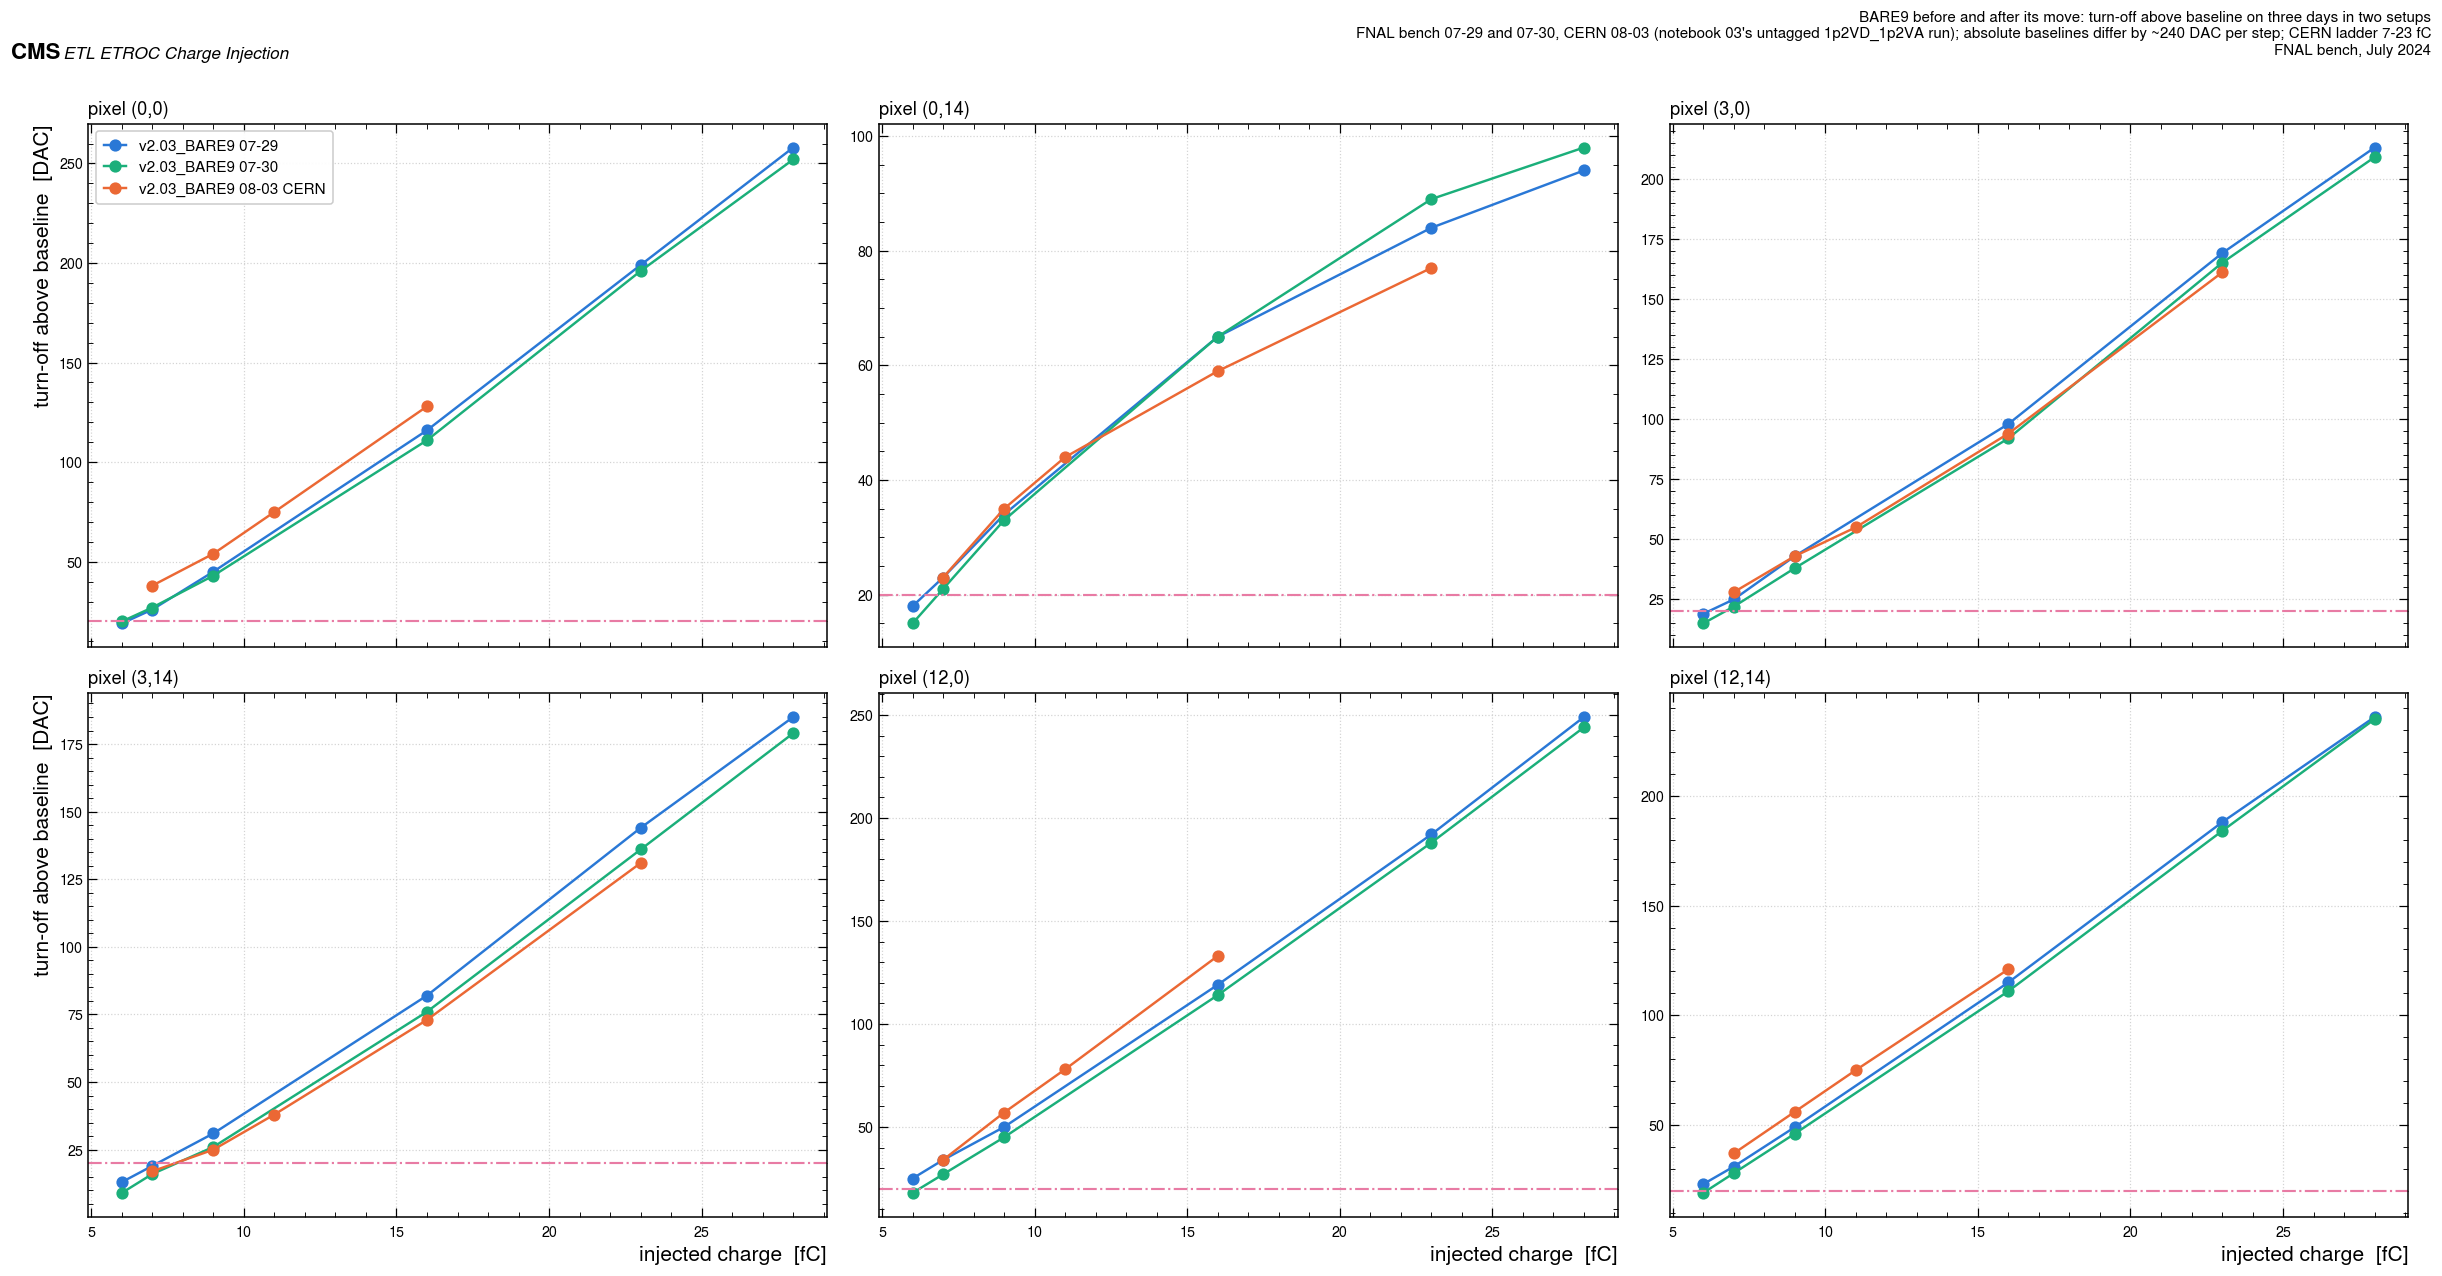

In [20]:
fig, axs = plt.subplots(2, 3, figsize=(22, 11), sharex=True)
acq3 = ["v2.03_BARE9 07-29", "v2.03_BARE9 07-30", "v2.03_BARE9 08-03 CERN"]
c3 = [Q.C_BLUE, Q.C_AQUA, Q.C_ORANGE]
for k, (r, c) in enumerate(Q.JUL_PIXELS):
    ax = axs.flat[k]
    for a, col in zip(acq3, c3):
        s = B9[(B9.acq == a) & (B9.row == r) & (B9.col == c) & ~B9.at_ceiling].sort_values("charge_fC")
        ax.plot(s.charge_fC, s.turnoff_offset, "-o", ms=7, lw=1.6, color=col, label=a)
    ax.set_title("pixel (%d,%d)" % (r, c), loc="left", fontsize=12)
    ax.axhline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=1.4)
    if k >= 3:
        ax.set_xlabel("injected charge  [fC]")
    if k % 3 == 0:
        ax.set_ylabel("turn-off above baseline  [DAC]")
    if k == 0:
        ax.legend(fontsize=10)
fig.tight_layout()
Q.fig_header(fig, "BARE9 before and after its move: turn-off above baseline on three days in two setups",
             tag="FNAL bench 07-29 and 07-30, CERN 08-03 (notebook 03's untagged 1p2VD_1p2VA run); absolute baselines differ by ~240 DAC per step; CERN ladder 7-23 fC",
             scale=0.62, campaign=Q.JUL_CAMPAIGN)
Q.save_fig(fig, "jul_fig5_bare9_three_acquisitions")
plt.show()

## 8. The threshold edge: S-curve width, noise width and ENC, per die

The shared-σ fit of notebooks 01–03 over the five good pixels and the four charges from 9 fC,
per acquisition; the table is the one section 6 built. `BARE9` on 07-29 reads the narrowest
edge and the narrowest noise FWHM of the campaign, on the day with the low baseline. With the
slope constant to 0.1 % between the two days, a width that changes is a change of
input-referred noise (ENC 626 → 716 e), i.e. of the front end's state — see section 7.

In [21]:
print(DIE[["acquisition", "n_curves", "sigma_dac", "sigma_sd", "fwhm_mean", "fwhm_rms", "gain_dac_per_fc", "ENC_e"]]
      .round(2).to_string(index=False))
DIE[["acquisition", "chip", "n_curves", "sigma_dac", "sigma_sd", "fwhm_mean", "ENC_e"]].to_csv(Q.OUTDIR / "jul_scurve_sigma.csv", index=False)

       acquisition  n_curves  sigma_dac  sigma_sd  fwhm_mean  fwhm_rms  gain_dac_per_fc  ENC_e
 v2.03_BARE1 07-15        20       1.06      0.08       2.68      1.27            10.80 612.70
 v2.03_BARE4 07-16        20       1.20      0.08       2.63      0.79            11.42 655.77
 v2.03_BARE4 07-17        20       1.36      0.10       2.70      0.57            11.41 743.90
 v2.03_BARE4 07-18         0        NaN       NaN        NaN       NaN            11.08    NaN
v2.01_BARE10 07-22        20       1.10      0.06       2.24      0.73            11.22 612.00
 v2.03_BARE9 07-29        20       0.98      0.06       2.00      0.87             9.77 625.82
 v2.03_BARE9 07-30        20       1.12      0.10       2.67      0.61             9.76 716.08


## 9. The money plot, per die

TOA jitter against threshold above baseline, one curve per charge, CAL-windowed moments,
median over the five pixels with the inter-quartile band, and the quantisation floor
`LSB/√12` at each die's own CAL. The construction is notebook 03 section 7's. All four dies
sit at CAL ≈ 170, i.e. a TOA code of 18.4 ps and a floor of 5.3 ps. At BL+20 and 16 fC the
v2.03 dies read 6.6–8.1 ps and the v2.01 die 5.8 ps — within a factor 1.5 of the floor, and by
23 fC the medians reach it; the revisions are indistinguishable here. A jitter *below* the
floor (07-30 at 28 fC) means the TOA distribution has collapsed into one code and is a limit,
not a measurement. 07-18 (no usable baseline) and 07-17 (too few pixels per offset for a
median) are both absent from the figure; the sixth panel is left blank.

In [22]:
M = PTS[(PTS.n_hits_cal >= 500) & (PTS.acq != "v2.03_BARE4 07-18")].copy()
M = M.merge(NOI[["acq", "row", "col", "BL"]], on=["acq", "row", "col"], how="left")
M = M[~((M.row == 0) & (M.col == 14))]
M = Q.add_tdc_derived(M, toa="toa_mean_cal", toa_sd="toa_std_cal", tot="tot_mean_cal", tot_sd="tot_std_cal",
                      cal="cal_mean_cal", nhit="n_hits_cal")
M["offset"] = M.dac - M.BL
CALM = M.groupby("acq").cal_mean_cal.median()
print("median CAL per acquisition:\n" + CALM.round(1).to_string())
JIT = Q.pooled_at_offsets(M, ["acq"], ["jitter_ps", "tot_ns", "tot_mean_cal", "cal_mean_cal"], bl_col="BL",
                          charge_col="charge_fC", offsets=Q.OFFS)
JIT["jitter_median"] = [M[(M.acq == a) & (M.charge_fC == q) & (M.offset == o)].jitter_ps.median()
                        for a, q, o in zip(JIT.acq, JIT.charge_fC, JIT.offset)]
JIT.to_csv(Q.OUTDIR / "jul_jitter_by_offset.csv", index=False)
j20 = JIT[JIT.offset == 20]
print("\nTOA jitter at BL+20 [ps], mean over pixels\n" + j20.pivot_table(index="charge_fC", columns="acq", values="jitter_ps_mean").round(1).to_string())
print("\nthe same, median\n" + j20.pivot_table(index="charge_fC", columns="acq", values="jitter_median").round(1).to_string())
print("\npixels contributing\n" + j20.pivot_table(index="charge_fC", columns="acq", values="jitter_ps_n").to_string())

median CAL per acquisition:
acq
v2.01_BARE10 07-22    169.0
v2.03_BARE1 07-15     169.0
v2.03_BARE4 07-16     171.0
v2.03_BARE4 07-17     173.5
v2.03_BARE9 07-29     172.7
v2.03_BARE9 07-30     172.6



TOA jitter at BL+20 [ps], mean over pixels
acq        v2.01_BARE10 07-22  v2.03_BARE1 07-15  v2.03_BARE4 07-16  v2.03_BARE4 07-17  v2.03_BARE9 07-29  v2.03_BARE9 07-30
charge_fC                                                                                                                   
6.0                      23.5               20.2               15.7               26.7               56.6                NaN
7.0                      10.9               15.1               10.9               13.8               27.8               48.1
9.0                       8.2               10.2               10.2               29.1               10.3               19.8
16.0                      5.8                7.4                8.1                5.8                6.6                6.6
23.0                      5.0                6.5                5.3                5.7                6.3                5.8
28.0                      6.7                5.0                4.8              

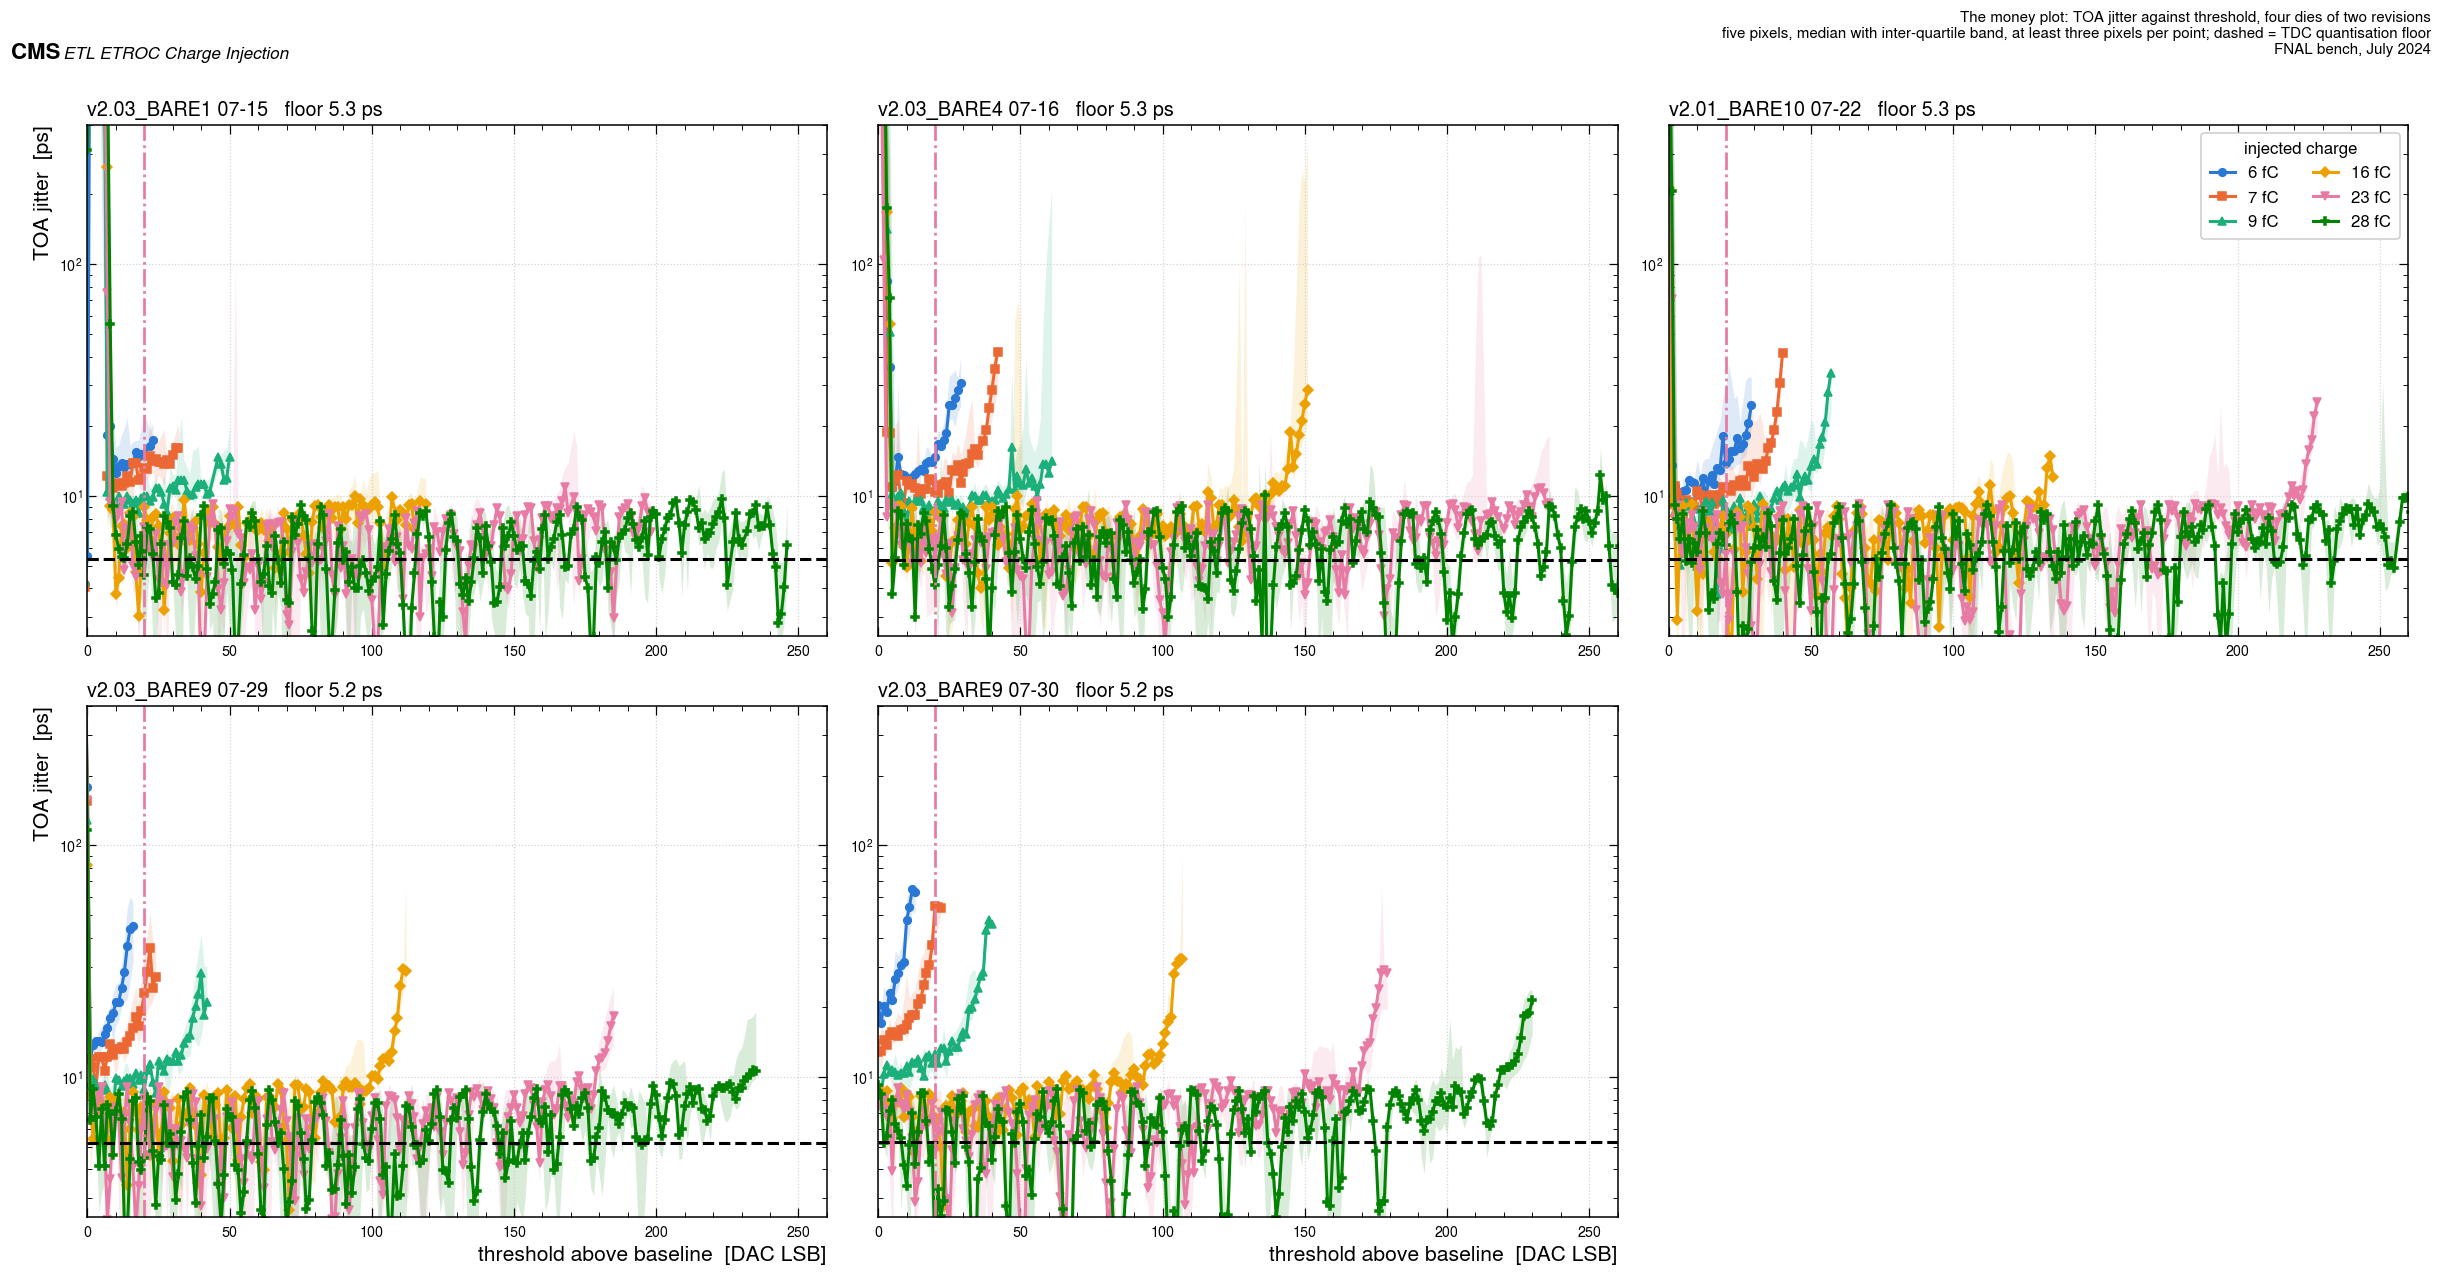

In [23]:
fig, axs = plt.subplots(2, 3, figsize=(22, 11))
PAN = ["v2.03_BARE1 07-15", "v2.03_BARE4 07-16", "v2.01_BARE10 07-22", "v2.03_BARE9 07-29", "v2.03_BARE9 07-30"]
axs.flat[5].axis("off")    # 07-17 (short day) and 07-18 (no baseline) are not shown
for k, acq in enumerate(PAN):
    ax = axs.flat[k]
    g = M[M.acq == acq]
    _, fl = Q.quantisation_floor_ps(g.cal_mean_cal.median())
    for ch in Q.JUL_CHARGES:
        sub = g[g.charge_fC == ch]
        if not len(sub):
            continue
        grp = sub.groupby("offset").jitter_ps
        med, q1, q3, n = grp.median(), grp.quantile(0.25), grp.quantile(0.75), grp.size()
        keep = n >= 3
        ax.plot(med.index[keep], med[keep], "-", marker=Q.CMK[ch], ms=5, lw=2.0, color=Q.CCOL[ch], label="%d fC" % ch)
        ax.fill_between(med.index[keep], q1[keep], q3[keep], color=Q.CCOL[ch], alpha=0.15, lw=0)
    ax.axhline(fl, color="black", ls="--", lw=2.0)
    ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=1.8)
    ax.set_yscale("log")
    ax.set_ylim(2.5, 400)
    ax.set_xlim(0, 260)
    ax.set_title("%s   floor %.1f ps" % (acq, fl), loc="left", fontsize=13)
    if k >= 3:
        ax.set_xlabel("threshold above baseline  [DAC LSB]")
    if k % 3 == 0:
        ax.set_ylabel("TOA jitter  [ps]")
    if k == 2:
        ax.legend(title="injected charge", ncol=2, fontsize=11, title_fontsize=11)
fig.tight_layout()
Q.fig_header(fig, "The money plot: TOA jitter against threshold, four dies of two revisions",
             tag="five pixels, median with inter-quartile band, at least three pixels per point; dashed = TDC quantisation floor",
             scale=0.62, campaign=Q.JUL_CAMPAIGN)
Q.save_fig(fig, "jul_fig6_money_plot")
plt.show()

## 10. Time over threshold at the operating point

TOT at BL+20 against charge, per die, in ns through each point's CAL. From 16 fC up all four
dies agree to within ~0.15 ns. At 6–7 fC the TOT scatters by ~0.7 ns across the acquisitions
with no revision ordering — the two `BARE9` days differ from each other by as much as either
differs from the v2.01 die — because the low-charge TOT is set by where BL+20 cuts each pulse,
and section 7 shows that operating point moved between days.

TOT at BL+20 [ns], mean over pixels
acq        v2.01_BARE10 07-22  v2.03_BARE1 07-15  v2.03_BARE4 07-16  v2.03_BARE4 07-17  v2.03_BARE9 07-29  v2.03_BARE9 07-30
charge_fC                                                                                                                   
6.0                      1.03               1.25               1.23               0.89               0.90                NaN
7.0                      1.38               1.40               1.45               1.17               0.88               0.71
9.0                      1.65               1.63               1.57               1.02               1.39               1.19
16.0                     1.90               1.94               1.87               1.69               1.81               1.77
23.0                     1.98               2.00               1.96               1.88               1.91               1.90
28.0                     2.02               2.02               2.00               1.89   

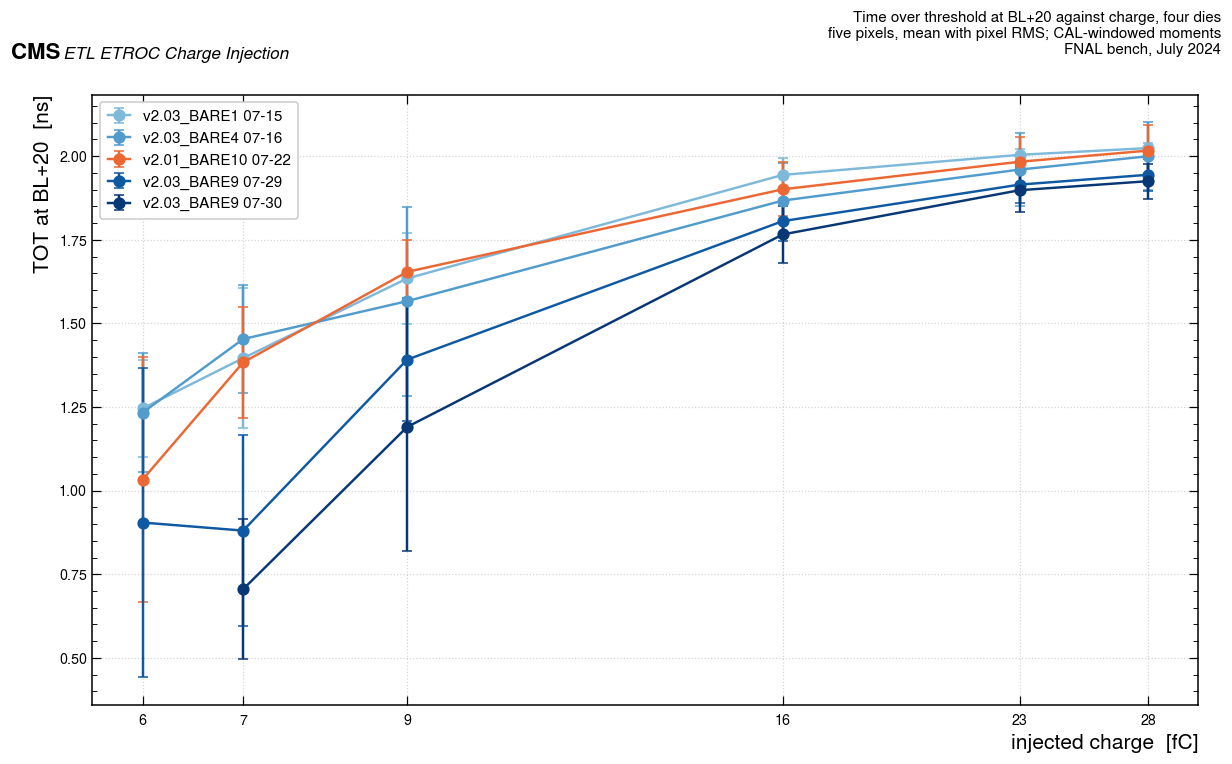

In [24]:
t20 = JIT[JIT.offset == 20]
print("TOT at BL+20 [ns], mean over pixels\n" + t20.pivot_table(index="charge_fC", columns="acq", values="tot_ns_mean").round(2).to_string())
t20[["acq", "charge_fC", "tot_ns_mean", "tot_ns_rms", "tot_ns_n", "tot_mean_cal_mean"]].to_csv(Q.OUTDIR / "jul_tot_at_bl20.csv", index=False)
fig, ax = plt.subplots(figsize=(11, 6.4))
for k, acq in enumerate(PAN):
    s = t20[t20.acq == acq].sort_values("charge_fC")
    ax.errorbar(s.charge_fC, s.tot_ns_mean, yerr=s.tot_ns_rms, fmt="-o", ms=7, lw=1.6, capsize=3,
                color=(Q.C_ORANGE if "v2.01" in acq else plt.cm.Blues(0.45 + 0.13 * k)), label=acq)
Q.charge_axis(ax, "x", Q.JUL_CHARGES)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOT at BL+20  [ns]")
ax.legend(fontsize=10)
fig.tight_layout()
Q.fig_header(fig, "Time over threshold at BL+20 against charge, four dies",
             tag="five pixels, mean with pixel RMS; CAL-windowed moments", scale=0.62, campaign=Q.JUL_CAMPAIGN)
Q.save_fig(fig, "jul_fig7_tot")
plt.show()

## 11. Summary

Everything pooled is over five pixels, (0,14) excluded, and "per die" averages the good days
of that die.

In [25]:
b10 = DIE[DIE.chip == "ET2p01_BARE10"].iloc[0]
v3 = DIE[(DIE.revision == "v2.03") & (DIE.acquisition != "v2.03_BARE4 07-18")]
j15 = j20[j20.charge_fC == 16].set_index("acq").jitter_ps_mean
SUMMARY = pd.DataFrame([
    dict(n=1, quantity="pixel (0,14) 9-28 fC chord relative to the other pixels, all campaigns", value="%.2f (range %.2f-%.2f)" % (P14.ratio.median(), P14.ratio.min(), P14.ratio.max()),
         unit="ratio", label="DERIVED; six dies, two revisions; a compressive response, not a scale (median k %.2f at 9 fC -> %.2f at 28 fC; %d of the 9 fC values are upper bounds)" % (RESULTS["pixel_0_14_k_at_9"], RESULTS["pixel_0_14_k_at_28"], RESULTS["pixel_0_14_k_at_9_n_clamped"])),
    dict(n=2, quantity="(0,14) noise: NW over array mean (four maps); FWHM over the column-14 control; S-curve sigma over the other pixels",
         value="%.2f; %.2f; %.2f" % (RESULTS["nw_maps_0_14_over_mean"], RESULTS["pixel_0_14_fwhm_ratio_col14"], RESULTS["pixel_0_14_sigma_ratio_median"]),
         unit="ratios", label="RAW maps exclude a 3x small-signal deficit only; FWHM and sigma say the front end's operating point differs"),
    dict(n=3, quantity="bias of a six-pixel pooled preamp gain from including (0,14)", value="x %.3f" % RESULTS["pooled_gain_bias_6px"],
         unit="factor (excl/incl)", label="DERIVED; applies to notebook 03's absolute gains; cause of the pixel's behaviour unresolved"),
    dict(n=4, quantity="preamp gain, v2.03 dies (BARE1, BARE4, BARE9), five pixels", value="%.1f, %.1f, %.1f" % tuple(v203.gain.values),
         unit="DAC/fC", label="DERIVED; die-to-die spread %.0f %%" % (100 * v203.gain.std(ddof=1) / v203.gain.mean())),
    dict(n=5, quantity="preamp gain, v2.01 die (BARE10), five pixels", value="%.1f ± %.1f" % (b10.gain_dac_per_fc, b10.gain_sem),
         unit="DAC/fC", label="DERIVED"),
    dict(n=6, quantity="preamp gain ratio v2.01 / v2.03, same bench", value="%.2f ± %.2f" % (r_gain, r_gain_err),
         unit="ratio", label="DERIVED; %.2f-%.2f if the DAC scale follows VRef, 1.00 if not; %.1f sigma (Student-t, 2 dof) from the former, or %.0f mV of unrecorded rail" % (PRED_BAND[0], PRED_BAND[1], RESULTS["rev_gain_gauss_sigma_equiv"], RESULTS["rev_gain_rail_equiv_mV"])),
    dict(n=7, quantity="S-curve sigma and noise FWHM, v2.01 / v2.03", value="%.2f, %.2f" % (r_sig, r_fwhm), unit="ratios", label="DERIVED; same two predictions; sigma near 1.0, FWHM on the VRef prediction"),
    dict(n=8, quantity="ENC, v2.03 dies / v2.01 die", value="%.0f, %.0f, %.0f / %.0f" % (*v203.ENC.values, b10.ENC_e),
         unit="e", label="DERIVED; under the assumed LSB the ratio is LSB-free"),
    dict(n=9, quantity="BARE9 9-16 fC chord, CERN 08-03 / bench 07-30, five pixels", value="%.3f (pixel spread %.3f)" % (RESULTS["bare9_gain_cern_over_bench"], RESULTS["bare9_gain_cern_over_bench_spread"]),
         unit="ratio", label="DERIVED; on the one chord the two ladders share; the die's response survived the move"),
    dict(n=10, quantity="BARE9 baseline steps, 07-29 -> 07-30 -> CERN 08-03", value="%+.0f, %+.0f" % (RESULTS["bare9_BL_shift_0730_minus_0729"], RESULTS["bare9_BL_shift_cern_minus_0730"]),
         unit="DAC", label="RAW; from the rail this would need ~%.1f V and a x%.0f slope change — not the rail; cause unknown, no register read-back" % (RESULTS["bare9_rail_for_240_dac_V"], RESULTS["bare9_gain_factor_for_that_rail"])),
    dict(n=11, quantity="TOA jitter at BL+20, 16 fC, per die (BARE1, BARE4, BARE10, BARE9 x2)", value=", ".join("%.1f" % j15[a] for a in PAN if a in j15.index),
         unit="ps", label="DERIVED; 1.1-1.5 x the %.1f ps floor; at the floor from 23 fC" % Q.quantisation_floor_ps(CALM.median())[1]),
    dict(n=12, quantity="BARE4 map baseline gradient, row 0 -> 15 and col 0 -> 15", value="%+.0f, %+.0f" % (
        MAP.groupby("row").bl_dac.mean().iloc[-1] - MAP.groupby("row").bl_dac.mean().iloc[0],
        MAP.groupby("col").bl_dac.mean().iloc[-1] - MAP.groupby("col").bl_dac.mean().iloc[0]),
         unit="DAC", label="RAW; noise width flat"),
])
print(SUMMARY.to_string(index=False))
SUMMARY.to_csv(Q.OUTDIR / "jul_summary_numbers.csv", index=False)
RESULTS["v203_gain_by_die"] = {k: float(v) for k, v in v203.gain.items()}
RESULTS["v201_gain"] = float(b10.gain_dac_per_fc)
RESULTS["enc_by_die"] = {k: float(v) for k, v in v203.ENC.items()}
RESULTS["enc_v201"] = float(b10.ENC_e)
with open(Q.OUTDIR / "jul_results.json", "w") as f:
    json.dump(RESULTS, f, indent=1)

 n                                                                                                           quantity                      value               unit                                                                                                                                                 label
 1                                             pixel (0,14) 9-28 fC chord relative to the other pixels, all campaigns     0.30 (range 0.16-0.48)              ratio DERIVED; six dies, two revisions; a compressive response, not a scale (median k 0.71 at 9 fC -> 0.44 at 28 fC; 2 of the 9 fC values are upper bounds)
 2 (0,14) noise: NW over array mean (four maps); FWHM over the column-14 control; S-curve sigma over the other pixels           0.96; 0.68; 0.52             ratios                                           RAW maps exclude a 3x small-signal deficit only; FWHM and sigma say the front end's operating point differs
 3                                                       b

## 12. Reproduction ledger

The July reduction has no hand-decode cross-check, so the ledger is internal: the per-day
directory counts in `jul_et2p03_configs.csv` against the three tables, the README's totals,
the decode-error count, and the `BARE4` autocalibration map against the same day's noise scans.
No row names a charge, so the charge convention does not enter it (the `published_label_fC`
column is empty).

In [26]:
LED = pd.DataFrame(LEDGER)
LED["|diff|"] = LED["diff"].abs()
print(LED[["quantity", "recomputed", "published", "|diff|", "tol", "unit", "agrees"]].round(3).to_string(index=False))
LED.to_csv(Q.OUTDIR / "jul_reproduction_ledger.csv", index=False)
print("\n%d of %d checks agree within tolerance." % (int(LED.agrees.sum()), len(LED)))

                                               quantity  recomputed  published  |diff|  tol     unit  agrees
     point directories accounted for, v2.03_BARE1 07-15    3712.000       3712   0.000    0     dirs    True
     point directories accounted for, v2.03_BARE4 07-16    4099.000       4099   0.000    0     dirs    True
     point directories accounted for, v2.03_BARE4 07-17    1143.000       1143   0.000    0     dirs    True
     point directories accounted for, v2.03_BARE4 07-18    3210.000       3210   0.000    0     dirs    True
    point directories accounted for, v2.01_BARE10 07-22    4155.000       4155   0.000    0     dirs    True
     point directories accounted for, v2.03_BARE9 07-29    3441.000       3441   0.000    0     dirs    True
     point directories accounted for, v2.03_BARE9 07-30    3290.000       3290   0.000    0     dirs    True
                               decoded points, all days   22756.000      22756   0.000    0   points    True
                   

---

## 13. Caveats

1. **No register read-back, no rail, no temperature, for any day.** The absolute baselines,
   and the ~240 DAC steps `BARE9` took between its three acquisitions, cannot be attributed.
   Slopes, widths and everything referred to a same-day baseline are what this campaign can
   compare; absolute DACs across days are not.
2. **One v2.01 die.** The revision comparison of section 6 has a die-to-die spread of ±8 % on the
   v2.03 side and nothing on the v2.01 side; it is a tension with the DAC-follows-VRef reading,
   not a rejection. The transfer-function measurement in the bench plan is the direct test.
3. **Pixel (0,14) is excluded from every pooled number here**, on the evidence of section 5,
   and its cause is not resolved: the response compresses above ~9 fC on six dies, the noise
   measurements point at the front end's operating point rather than the injector, and no
   register read-back exists to say why. January's twelve-pixel data also put all of row 0 low,
   so a position dependence is not confined to one corner; only same-pixel ratios between dies
   are free of it.
6. **Every "gain" is a chord slope over a stated range.** The straight line is rejected on every
   pixel (section 4), so slopes over different ranges are not interchangeable — which is why
   section 7 uses the one chord its three acquisitions share, and why the per-pixel fit errors
   are quoted with and without the √(χ²/ndf) scaling.
4. **07-18 has no usable noise scan** and 07-17 is a short day. `BARE4`'s numbers rest on 07-16
   with 07-17 as the repeat.
5. **The DAC LSB is assumed** (0.3906 mV) wherever a millivolt or an electron appears, exactly as
   in notebooks 01–03, and section 6 is the first measurement in the folder that bears on
   whether it is the same number on both revisions.